# Metaheurísticas vs Grid Search, Random Search y Búsqueda Bayesiana

En Machine Learning, cuando hay que ajustar hiperparámetros se usan casi siempre tres métodos: **Grid Search**, **Random Search** y **optimización bayesiana**. Las metaheurísticas de las notebooks anteriores (ES, AG, DE, PSO, SA) resuelven *el mismo problema*: minimizar una función de pérdida costosa y opaca sobre un espacio de configuraciones.

Esta notebook los pone frente a frente, con las mismas reglas:

- **Mismo presupuesto** de evaluaciones para todos.
- **Mismas funciones objetivo**, primero sintéticas (baratas, con muchas repeticiones) y luego tres tareas reales de ML (SVM, Gradient Boosting y MLP).
- **Muchas semillas** y estadística honesta, no una sola corrida.

El objetivo no es coronar un ganador. Es entender **en qué situaciones** conviene cada familia y por qué.

## Contenido

1. Los dos bandos y qué suponen del problema
2. Formalización: presupuesto, regret y espacio normalizado
3. Los tres clásicos desde cero: Grid, Random y Bayesiana (GP + EI y TPE)
4. Las metaheurísticas, en versión compacta
5. Ejecutor común y prueba de cordura
6. Experimento A: paisajes sintéticos tipo HPO
7. Experimento B: efecto de la dimensión del espacio
8. Experimento C: tres tareas reales de ML
9. Resumen global, costo del optimizador y sobreajuste a la validación
10. Guía de decisión, resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Qué vas a aprender**

- Por qué Grid Search falla al crecer la dimensión y por qué Random Search es una línea base tan fuerte (Bergstra & Bengio, 2012).
- Cómo funciona por dentro la optimización bayesiana (proceso gaussiano + mejora esperada) y su variante TPE, y cuánto cuesta ejecutarlas.
- En qué paisajes ganan las metaheurísticas y en cuáles no.
- Cómo medir la comparación bien: mismo presupuesto, repeticiones, rangos promedio, pruebas no paramétricas y el sesgo de seleccionar sobre la validación.

**Prerrequisitos**

- [Notebook 16 · Hiperparámetros de ML con metaheurísticas](16-hiperparametros-ml-metaheuristicas.ipynb): HPO como caja negra en una serie temporal. Esta notebook la complementa con más tareas, más presupuesto y los clásicos en el centro.
- [Notebook 14 · Medición de desempeño](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb) y [11 · PSO y DE](../03-metodos-poblacionales/11-enjambre-pso-evolucion-diferencial.ipynb).
- [Notebook 05 · Recocido simulado](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb) y [09 · Algoritmos genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb).

In [1]:
import os
# Un hilo por proceso: evitamos que BLAS/OpenMP compitan con el paralelismo por procesos
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[v] = "1"

import time, warnings, itertools
from joblib import Parallel, delayed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import cho_factor, cho_solve, solve_triangular, LinAlgError
from scipy.stats import norm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
SEMILLA_BASE = 2024
NPROC = min(10, os.cpu_count() or 2)
print("procesos disponibles para los experimentos:", NPROC)

procesos disponibles para los experimentos: 10


## 1. Los dos bandos y qué suponen del problema

Todos estos métodos ven la pérdida de validación $f(\lambda)$ como una **caja negra**: pueden evaluarla, no derivarla. Lo que cambia es *cuánto estructura le suponen*.

| Método | Qué hace | Qué supone del problema | Usa el historial | Costo propio por iteración |
|---|---|---|---|---|
| **Grid Search** | Evalúa una malla regular | Que cada eje importa por igual y que la malla es suficientemente fina | No | Nulo |
| **Random Search** | Muestrea al azar, uniforme | Casi nada | No | Nulo |
| **Bayesiana (GP + EI)** | Ajusta un proceso gaussiano a las evaluaciones y evalúa donde la mejora esperada es mayor | Que $f$ es **suave**; pocas dimensiones continuas | Sí, todo | Alto: $O(n^3)$ por el ajuste del GP |
| **Bayesiana (TPE)** | Modela $p(\lambda\mid f\text{ bueno})$ y $p(\lambda\mid f\text{ malo})$ con densidades de Parzen | Dimensiones casi independientes; admite espacios condicionales | Sí, todo | Bajo |
| **ES (1+1)** | Mutación gaussiana con regla del 1/5 | Que hay estructura local | Solo el actual | Nulo |
| **AG / DE / PSO** | Población que se recombina o se mueve | Que cruzar soluciones buenas da soluciones buenas | La población | Nulo |
| **Recocido simulado** | Camino que acepta empeoramientos con probabilidad decreciente | Estructura local y óptimos locales superables | Solo el actual | Nulo |

Cuando cada evaluación cuesta minutos u horas, el costo propio del optimizador no importa. Cuando cuesta milisegundos, sí (sección 9).

Dos ideas guiarán todo el análisis:

1. **Dimensión efectiva.** En muchos problemas de ML solo unos pocos hiperparámetros importan de verdad (la tasa de aprendizaje, por ejemplo). Grid desperdicia evaluaciones repitiendo valores de los ejes irrelevantes; Random no.
2. **Suavidad y cliffs.** La bayesiana con GP supone suavidad. Los hiperparámetros reales tienen *acantilados* (una tasa de aprendizaje demasiado alta diverge) y zonas planas, que violan ese supuesto.

## 2. Formalización: presupuesto, regret y espacio normalizado

Sea $\Lambda$ el espacio de configuraciones y $f:\Lambda\to\mathbb{R}$ la pérdida (a minimizar). Cada método dispone de un **presupuesto** de $B$ evaluaciones. Si $\lambda_1,\dots,\lambda_B$ son las configuraciones evaluadas, el resultado es el mejor valor visto:

$$
\hat f_B = \min_{t\le B} f(\lambda_t), \qquad
r_B = \hat f_B - f^\star \ \ (\text{regret simple}),
$$

con $f^\star$ el mínimo global (cuando se conoce). La curva $t\mapsto \hat f_t$ es la **curva de convergencia anytime**: muestra qué método es mejor para cada presupuesto, no solo al final.

**Espacio normalizado.** Todos los optimizadores trabajan en el cubo unitario $u\in[0,1]^d$, y un *decodificador* lo convierte en hiperparámetros reales:

| Tipo | Decodificación |
|---|---|
| continuo | $\lambda = \ell + u\,(h-\ell)$ |
| logarítmico | $\lambda = \exp\big(\ln\ell + u\,(\ln h-\ln\ell)\big)$ |
| entero | $\lambda = \operatorname{round}(\ell + u\,(h-\ell))$ |
| categórico con $k$ valores | $\lambda = c_{\lfloor uk\rfloor}$ |

Así todos los métodos ven exactamente el mismo problema. Un detalle que importa: una variable categórica queda como un eje continuo con una **falsa noción de orden y distancia**. A la bayesiana con GP le perjudica más que a los demás.

**Reglas del ejecutor** (clase `Evaluador`):

- Cuenta cada evaluación **distinta**. Si el optimizador pide una configuración ya evaluada (frecuente en espacios discretos), se devuelve el valor guardado sin gastar presupuesto, como se haría con una caché real.
- Registra la curva *anytime*, el tiempo gastado en evaluar y el tiempo total, para medir el costo del propio optimizador.

In [2]:
class Agotado(Exception):
    '''Se lanza cuando el presupuesto de evaluaciones se acabó.'''


class Evaluador:
    '''Envuelve la función objetivo con presupuesto, caché y registro de la curva anytime.'''

    def __init__(self, f, d, B, clave=None):
        self.f, self.d, self.B = f, d, B
        self.clave = clave or (lambda u: tuple(np.round(u, 9)))
        self.cache, self.hits, self.n = {}, 0, 0
        self.best, self.best_u = np.inf, None
        self.curva, self.t_eval = [], 0.0

    def __call__(self, u):
        u = np.clip(np.asarray(u, dtype=float), 0.0, 1.0)
        k = self.clave(u)
        if k in self.cache:                      # configuración repetida: no cuesta presupuesto
            self.hits += 1
            if self.hits > 20 * self.B:          # protección contra bucles sin información nueva
                raise Agotado
            return self.cache[k]
        if self.n >= self.B:
            raise Agotado
        t0 = time.perf_counter()
        y = float(self.f(u))
        self.t_eval += time.perf_counter() - t0
        self.n += 1
        self.cache[k] = y
        if y < self.best:
            self.best, self.best_u = y, u.copy()
        self.curva.append(self.best)
        return y


class Espacio:
    '''Decodifica u en [0,1]^d a hiperparámetros reales. dims = lista de tuplas:
    (nombre, "float"|"log"|"int", lo, hi)  o  (nombre, "cat", [valores]).'''

    def __init__(self, dims):
        self.dims, self.d = dims, len(dims)

    def decodificar(self, u):
        cfg = {}
        for x, dim in zip(u, self.dims):
            nombre, tipo = dim[0], dim[1]
            if tipo == "cat":
                op = dim[2]; cfg[nombre] = op[min(int(x * len(op)), len(op) - 1)]
            else:
                lo, hi = dim[2], dim[3]
                if tipo == "log":
                    cfg[nombre] = float(np.exp(np.log(lo) + x * (np.log(hi) - np.log(lo))))
                elif tipo == "int":
                    cfg[nombre] = int(round(lo + x * (hi - lo)))
                else:
                    cfg[nombre] = float(lo + x * (hi - lo))
        return cfg

    def clave(self, u):
        '''Dos u que decodifican igual comparten clave (caché por configuración real).'''
        return tuple((k, round(v, 8) if isinstance(v, float) else v) for k, v in self.decodificar(u).items())


# Prueba rápida del decodificador
esp_demo = Espacio([("C", "log", 1e-2, 1e3), ("kernel", "cat", ["rbf", "poly", "sigmoid"]), ("degree", "int", 2, 5)])
for u in ([0.0, 0.0, 0.0], [0.5, 0.5, 0.5], [1.0, 0.99, 1.0]):
    print(u, "->", esp_demo.decodificar(np.array(u)))

[0.0, 0.0, 0.0] -> {'C': 0.010000000000000005, 'kernel': 'rbf', 'degree': 2}
[0.5, 0.5, 0.5] -> {'C': 3.162277660168378, 'kernel': 'poly', 'degree': 4}
[1.0, 0.99, 1.0] -> {'C': 999.9999999999989, 'kernel': 'sigmoid', 'degree': 5}


## 3. Los tres clásicos desde cero

### 3.1 Grid Search y Random Search

**Grid Search.** Con $d$ hiperparámetros y $n$ niveles por eje hay $n^d$ puntos. Con un presupuesto $B$ solo caben $n=\lfloor B^{1/d}\rfloor$ niveles por eje. Con $B=100$:

| $d$ | niveles por eje que caben |
|---|---|
| 2 | 10 |
| 4 | 3 |
| 6 | 2 |
| 8 | 1 |

A partir de $d\approx 6$ la malla ya no puede ni siquiera tocar los dos extremos de cada eje. Cuando $n^d > B$ hay que decidir qué puntos de la malla evaluar. Aquí se toma $n=\lceil B^{1/d}\rceil$ y se **evalúa una muestra aleatoria de $B$ puntos de la malla completa**, sin truncarla en orden lexicográfico (que dejaría ejes sin explorar). Es la versión *más favorable* para Grid.

**Random Search.** Muestrea $u\sim\mathcal U[0,1]^d$. Bergstra & Bengio (2012) mostraron por qué funciona: si solo $d_e\ll d$ hiperparámetros importan, $B$ puntos aleatorios exploran $B$ valores distintos de cada eje importante, mientras que una malla de $B$ puntos solo explora $B^{1/d}$.

La probabilidad de que Random Search obtenga al menos un punto dentro del mejor $\varepsilon$ del espacio (en volumen) es

$$
P = 1-(1-\varepsilon)^B ,
$$

independiente de la dimensión. Con $\varepsilon=5\%$ y $B=60$ evaluaciones, $P\approx 95\%$. Pero **el mejor 5% del volumen puede no ser suficientemente bueno**: Random garantiza cercanía en rango, no en valor.

In [3]:
def grid_search(ev, rng):
    '''Malla regular con n = ceil(B^(1/d)) niveles por eje (centros de celda).
    Si la malla excede el presupuesto se evalúa una muestra aleatoria de B puntos de ella.'''
    d, B = ev.d, ev.B
    n = max(2, int(np.ceil(B ** (1.0 / d))))
    niveles = (np.arange(n) + 0.5) / n
    total = n ** d
    idx = rng.choice(total, size=B, replace=False) if total > B else np.arange(total)
    for k in idx:
        coords = np.unravel_index(int(k), (n,) * d)
        ev(niveles[list(coords)])


def random_search(ev, rng):
    while True:
        ev(rng.random(ev.d))


# Cuántos puntos distintos de cada eje ve cada método (B=60, d=6, ejes importantes: 2)
B, d = 60, 6
n = int(np.ceil(B ** (1 / d)))
print(f"Grid:   {n} niveles por eje -> {n} valores distintos por eje importante")
print(f"Random: {B} valores distintos por eje importante")
print(f"P(Random toque el mejor 5% del volumen con B={B}) = {1 - 0.95**B:.3f}")

Grid:   2 niveles por eje -> 2 valores distintos por eje importante
Random: 60 valores distintos por eje importante
P(Random toque el mejor 5% del volumen con B=60) = 0.954


### 3.2 Optimización bayesiana con proceso gaussiano (GP + EI)

La idea es **construir un modelo barato de $f$** a partir de las evaluaciones hechas y usarlo para decidir cuál evaluar a continuación.

**Modelo sustituto.** Se supone que $f\sim\mathcal{GP}(m,k)$. Con observaciones $\mathbf{y}$ en los puntos $X$, la distribución predictiva en un punto nuevo $u$ es normal:

$$
\mu(u) = \mathbf{k}_*^\top K^{-1}\mathbf{y}, \qquad
\sigma^2(u) = k(u,u)-\mathbf{k}_*^\top K^{-1}\mathbf{k}_* ,
$$

con $K_{ij}=k(u_i,u_j)+\sigma_n^2\delta_{ij}$ y $\mathbf k_*=[k(u,u_i)]_i$. Se usa el **kernel de Matérn 5/2**, menos exigente en suavidad que el gaussiano:

$$
k(r)=\Big(1+\sqrt5\,r+\tfrac53 r^2\Big)e^{-\sqrt5\,r},\qquad r=\frac{\|u-u'\|}{\ell}.
$$

La escala $\ell$ se elige entre cuatro valores maximizando la *verosimilitud marginal*

$$
\ln p(\mathbf y\mid X,\ell) = -\tfrac12\,\mathbf y^\top K^{-1}\mathbf y-\tfrac12\ln|K|-\tfrac n2\ln 2\pi .
$$

**Función de adquisición: mejora esperada (EI).** Para minimización, con $f_{\min}$ el mejor valor visto y $z=\dfrac{f_{\min}-\mu(u)}{\sigma(u)}$:

$$
\operatorname{EI}(u) = \big(f_{\min}-\mu(u)\big)\,\Phi(z)+\sigma(u)\,\varphi(z).
$$

El primer término premia **explotar** (media baja); el segundo premia **explorar** (incertidumbre alta). El siguiente punto es $u_{t+1}=\arg\max_u \operatorname{EI}(u)$, que se busca sobre 1 500 candidatos aleatorios más 300 perturbaciones de los tres mejores puntos.

**Costo.** Factorizar $K$ cuesta $O(n^3)$. Con $n=100$ evaluaciones es trivial; con miles de evaluaciones, prohibitivo. Es el precio de usar *toda* la información.

```
función BO_GP(f, B):
    evaluar n0 puntos aleatorios
    mientras evaluaciones < B:
        ajustar GP (elegir ℓ por verosimilitud marginal)
        elegir u* = argmax EI(u) sobre candidatos
        evaluar f(u*) y añadir al historial
    retornar el mejor visto
```

escala elegida ls = 0.1 | error de interpolación en los puntos observados: 1.16e-04


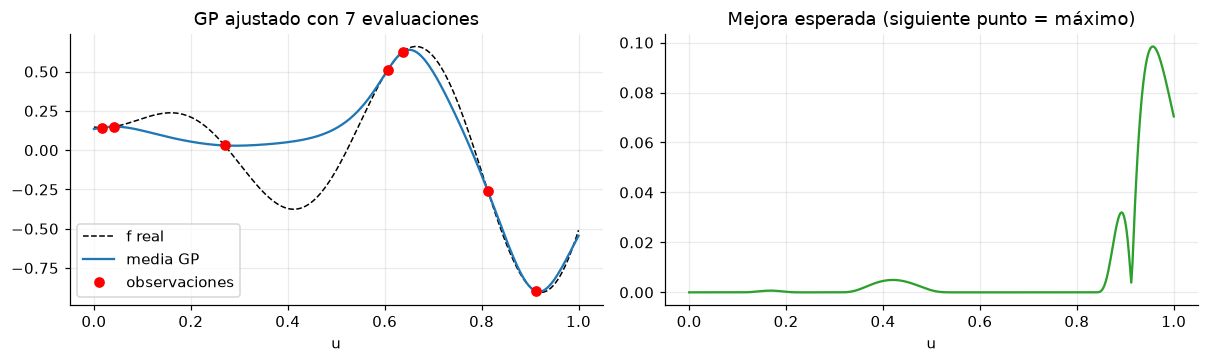

In [4]:
def _matern52(A, Bm, ls):
    r = np.sqrt(np.maximum(((A[:, None, :] - Bm[None, :, :]) ** 2).sum(-1), 0.0)) / ls
    return (1 + np.sqrt(5) * r + 5.0 * r ** 2 / 3.0) * np.exp(-np.sqrt(5) * r)


LS_GRID = np.array([0.1, 0.2, 0.4, 0.8])


def _gp_ajustar(X, y, ruido=1e-4):
    '''Ajusta un GP Matérn 5/2 (escala elegida por verosimilitud marginal). Devuelve None si falla.'''
    mu, sd = y.mean(), y.std() + 1e-12
    z = (y - mu) / sd
    n, mejor = len(z), None
    for ls in LS_GRID * np.sqrt(X.shape[1]):
        K = _matern52(X, X, ls) + ruido * np.eye(n)
        try:
            c = cho_factor(K, lower=True)
        except LinAlgError:
            continue
        a = cho_solve(c, z)
        lml = -0.5 * z @ a - np.log(np.diag(c[0])).sum() - 0.5 * n * np.log(2 * np.pi)
        if mejor is None or lml > mejor[0]:
            mejor = (lml, ls, c, a)
    return None if mejor is None else (mejor, mu, sd, z)


def _mejora_esperada(ajuste, X, cand):
    (lml, ls, c, a), mu, sd, z = ajuste
    Ks = _matern52(cand, X, ls)
    media = Ks @ a
    v = solve_triangular(c[0], Ks.T, lower=True)
    sigma = np.sqrt(np.maximum(1.0 - (v ** 2).sum(0), 1e-12))
    zz = (z.min() - media) / sigma
    return (z.min() - media) * norm.cdf(zz) + sigma * norm.pdf(zz)


def bayesiana_gp(ev, rng, n_cand=1500):
    d = ev.d
    n0 = max(4, min(10, ev.B // 5))
    X = [rng.random(d) for _ in range(n0)]
    Y = [ev(x) for x in X]
    while True:
        Xa, Ya = np.array(X), np.array(Y)
        ajuste = _gp_ajustar(Xa, Ya)
        if ajuste is None:
            u = rng.random(d)
        else:
            elite = Xa[np.argsort(Ya)[:3]].repeat(100, axis=0)
            cand = np.vstack([rng.random((n_cand, d)),
                              np.clip(elite + 0.08 * rng.standard_normal(elite.shape), 0, 1)])
            u = cand[np.argmax(_mejora_esperada(ajuste, Xa, cand))]
        X.append(u)
        Y.append(ev(u))


# Verificación en 1D: el GP interpola y la EI se concentra cerca del óptimo
f1 = lambda u: float(np.sin(12 * u[0]) * u[0] + 0.3 * (u[0] - 0.7) ** 2)
rng_t = np.random.default_rng(0)
Xo = rng_t.random((7, 1)); Yo = np.array([f1(x) for x in Xo])
aj = _gp_ajustar(Xo, Yo)
grid_u = np.linspace(0, 1, 400)[:, None]
ei = _mejora_esperada(aj, Xo, grid_u)
(lml, ls, c, a), mu_, sd_, z_ = aj
mu_pred = (_matern52(grid_u, Xo, ls) @ a) * sd_ + mu_
print("escala elegida ls =", round(ls / np.sqrt(1), 3), "| error de interpolación en los puntos observados:",
      f"{np.abs((_matern52(Xo, Xo, ls) @ a) * sd_ + mu_ - Yo).max():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(grid_u, [f1(x) for x in grid_u], "k--", lw=1, label="f real")
ax[0].plot(grid_u, mu_pred, label="media GP"); ax[0].plot(Xo, Yo, "ro", label="observaciones"); ax[0].legend()
ax[0].set_title("GP ajustado con 7 evaluaciones")
ax[1].plot(grid_u, ei, color="tab:green"); ax[1].set_title("Mejora esperada (siguiente punto = máximo)")
for a_ in ax: a_.set_xlabel("u")
plt.tight_layout(); plt.show()

### 3.3 Optimización bayesiana con TPE (Tree-structured Parzen Estimator)

TPE (Bergstra et al., 2011) es el algoritmo por defecto de Hyperopt y de Optuna. En vez de modelar $p(y\mid\lambda)$ como el GP, **invierte el modelo**: parte las observaciones en las **buenas** (el mejor $\gamma$, aquí 25 %) y las **malas**, y estima dos densidades por dimensión:

$$
p(\lambda\mid y)=\begin{cases}\ell(\lambda) & y<y^\gamma\\ g(\lambda) & y\ge y^\gamma\end{cases}
$$

con estimadores de Parzen (mezcla de gaussianas centradas en los puntos, más una componente uniforme de *prior*). Se demuestra que maximizar la mejora esperada equivale a maximizar el cociente

$$
\frac{\ell(\lambda)}{g(\lambda)} .
$$

Se generan candidatos muestreando de $\ell$ y se elige el de mayor $\ell/g$. Como las densidades se tratan **por dimensión**, el costo es lineal en $n$ y admite fácilmente espacios categóricos y condicionales. El precio es que **ignora las interacciones** entre hiperparámetros.

In [5]:
def _log_kde(x, pts, bw):
    '''log-densidad de Parzen (gaussianas + 1 componente uniforme de prior) evaluada en x (m,).'''
    k = len(pts)
    dens = np.exp(-0.5 * ((x[:, None] - pts[None, :]) / bw) ** 2) / (bw * np.sqrt(2 * np.pi))
    return np.log((dens.sum(1) + 1.0) / (k + 1) + 1e-300)


def _ancho(P):
    return np.clip(1.06 * P.std(0) * len(P) ** (-0.2), 0.03, 0.3)


def tpe(ev, rng, gamma=0.25, n_cand=48):
    d = ev.d
    n0 = max(4, min(10, ev.B // 5))
    X = [rng.random(d) for _ in range(n0)]
    Y = [ev(x) for x in X]
    while True:
        Xa, Ya = np.array(X), np.array(Y)
        o = np.argsort(Ya)
        ng = max(2, int(np.ceil(gamma * len(Ya))))
        buenos, malos = Xa[o[:ng]], Xa[o[ng:]]
        bwg, bwb = _ancho(buenos), _ancho(malos)
        # candidatos: por dimensión, se elige un punto bueno al azar y se perturba con el ancho de banda de l
        filas = rng.integers(ng, size=(n_cand, d))
        cand = np.clip(buenos[filas, np.arange(d)] + bwg * rng.standard_normal((n_cand, d)), 0, 1)
        score = np.zeros(n_cand)
        for j in range(d):
            score += _log_kde(cand[:, j], buenos[:, j], bwg[j]) - _log_kde(cand[:, j], malos[:, j], bwb[j])
        u = cand[np.argmax(score)]
        X.append(u)
        Y.append(ev(u))

## 4. Las metaheurísticas, en versión compacta

Son las mismas de las notebooks anteriores, reducidas a lo esencial para trabajar sobre el cubo unitario y con presupuestos pequeños. Para que la comparación sea justa, **ninguna se ajustó para las funciones de esta notebook**: se usan los valores por defecto de la literatura.

| Método | Esquema | Parámetros |
|---|---|---|
| **ES (1+1)** | $x'=x+\sigma\,\mathcal N(0,I)$; acepta si $f(x')\le f(x)$; regla del 1/5 | $\sigma_0=0.2$ |
| **AG** (estado estable) | torneo binario, cruce uniforme, mutación gaussiana, reemplaza al peor si mejora | $\mu=\operatorname{clip}(B/5,\,6,\,12)$ |
| **DE** `rand/1/bin` | $v=x_a+F(x_b-x_c)$, cruce binomial, selección uno a uno | $F=0.6,\ CR=0.8$ |
| **PSO** | $v\leftarrow w v+c_1 r_1(p-x)+c_2 r_2(g-x)$ (actualización asíncrona) | $w=0.72,\ c_1=c_2=1.49$ |
| **SA** | vecino gaussiano; acepta con prob. $e^{-\Delta/T}$; enfriamiento geométrico | $T_0=0.5\,s,\ T_f=0.005\,s$, con $s$ la desviación de las primeras evaluaciones |

La **temperatura del recocido se calibra con la escala de la función** ($s$), porque cada tarea tiene unidades distintas (error de clasificación, log-loss, RMSE). Es la única forma de que SA no dependa de las unidades.

**Presupuestos pequeños y poblaciones.** Con $B=40$ evaluaciones, una población de 12 gasta el 30 % del presupuesto solo en inicializarse. Por eso $\mu$ crece con $B$ pero se acota a $[6,12]$. Este es el verdadero punto débil de las metaheurísticas poblacionales en HPO.

In [6]:
def _mu(ev):
    return int(np.clip(ev.B // 5, 6, 12))


def estrategia_evolutiva(ev, rng):
    d = ev.d
    x = rng.random(d); fx = ev(x); sigma = 0.2
    while True:
        y = np.clip(x + sigma * rng.standard_normal(d), 0, 1)
        fy = ev(y)
        if fy <= fx:
            x, fx = y, fy; sigma = min(sigma * 1.5, 0.5)           # éxito: ampliar
        else:
            sigma = max(sigma * 1.5 ** (-0.25), 0.01)              # fracaso: reducir (equilibrio en p=1/5)


def algoritmo_genetico(ev, rng):
    d, mu = ev.d, _mu(ev)
    P = rng.random((mu, d)); F = np.array([ev(p) for p in P])
    pm = max(1.0 / d, 0.2)
    while True:
        i = rng.choice(mu, 2, replace=False); p1 = P[i[np.argmin(F[i])]]
        j = rng.choice(mu, 2, replace=False); p2 = P[j[np.argmin(F[j])]]
        h = np.where(rng.random(d) < 0.5, p1, p2)                   # cruce uniforme
        m = rng.random(d) < pm
        h = np.clip(h + m * 0.1 * rng.standard_normal(d), 0, 1)     # mutación gaussiana
        fh = ev(h); w = np.argmax(F)
        if fh < F[w]:
            P[w], F[w] = h, fh


def evolucion_diferencial(ev, rng, Fm=0.6, CR=0.8):
    d, mu = ev.d, _mu(ev)
    P = rng.random((mu, d)); fit = np.array([ev(p) for p in P])
    while True:
        for i in range(mu):
            a, b, c = rng.choice([k for k in range(mu) if k != i], 3, replace=False)
            v = np.clip(P[a] + Fm * (P[b] - P[c]), 0, 1)
            cr = rng.random(d) < CR; cr[rng.integers(d)] = True
            u = np.where(cr, v, P[i]); fu = ev(u)
            if fu <= fit[i]:
                P[i], fit[i] = u, fu


def enjambre_pso(ev, rng, w=0.72, c1=1.49, c2=1.49, vmax=0.3):
    d, n = ev.d, _mu(ev)
    X = rng.random((n, d)); V = rng.uniform(-0.1, 0.1, (n, d))
    f = np.array([ev(x) for x in X])
    pb, fpb = X.copy(), f.copy()
    g, fg = pb[np.argmin(fpb)].copy(), fpb.min()
    while True:
        for i in range(n):
            r1, r2 = rng.random(d), rng.random(d)
            V[i] = np.clip(w * V[i] + c1 * r1 * (pb[i] - X[i]) + c2 * r2 * (g - X[i]), -vmax, vmax)
            X[i] = np.clip(X[i] + V[i], 0, 1)
            fi = ev(X[i])
            if fi < fpb[i]:
                pb[i], fpb[i] = X[i].copy(), fi
            if fi < fg:
                g, fg = X[i].copy(), fi


def recocido_simulado(ev, rng, sigma=0.12):
    d = ev.d
    n0 = min(5, max(2, ev.B // 8))
    X0 = rng.random((n0, d)); F0 = np.array([ev(x) for x in X0])
    s = F0.std() if F0.std() > 0 else 1e-3
    T0, Tf = 0.5 * s, 0.005 * s
    x, fx = X0[np.argmin(F0)].copy(), F0.min()
    N, k = max(ev.B - n0, 1), 0
    while True:
        T = T0 * (Tf / T0) ** (min(k, N) / N); k += 1
        y = np.clip(x + sigma * rng.standard_normal(d), 0, 1); fy = ev(y)
        if fy <= fx or rng.random() < np.exp(-(fy - fx) / T):
            x, fx = y, fy

## 5. Ejecutor común y prueba de cordura

`correr_uno` ejecuta un método sobre una tarea con una semilla y un presupuesto, y devuelve la curva *anytime*, el mejor valor y los tiempos. `correr_lote` reparte las corridas entre procesos con `joblib` (backend `loky`, el mismo que usa scikit-learn; funciona en macOS, Linux, Windows y Colab).

Antes de comparar, una **prueba de cordura**: sobre una esfera de 4 dimensiones, todos los métodos deben respetar el presupuesto, devolver puntos dentro del cubo y ganarle a un muestreo de un solo punto.

In [7]:
ALGOS = {
    "Grid": grid_search,
    "Random": random_search,
    "BO-GP": bayesiana_gp,
    "TPE": tpe,
    "ES(1+1)": estrategia_evolutiva,
    "AG": algoritmo_genetico,
    "DE": evolucion_diferencial,
    "PSO": enjambre_pso,
    "SA": recocido_simulado,
}
CLASICOS = ["Grid", "Random", "BO-GP", "TPE"]
METAHEUR = ["ES(1+1)", "AG", "DE", "PSO", "SA"]
COLOR = {"Grid": "#7f7f7f", "Random": "#1f77b4", "BO-GP": "#17becf", "TPE": "#2ca02c",
         "ES(1+1)": "#d62728", "AG": "#ff7f0e", "DE": "#9467bd", "PSO": "#e377c2", "SA": "#8c564b"}
ESTILO = {a: ("-" if a in METAHEUR else "--") for a in ALGOS}

TAREAS = {}      # nombre -> dict(f=callable, d=int, clave=callable|None, ref=float|None)


def correr_uno(args):
    warnings.filterwarnings("ignore")        # los procesos de loky no heredan el filtro del cuaderno
    tarea, alg, semilla, B = args
    T = TAREAS[tarea]
    ev = Evaluador(T["f"], T["d"], B, T.get("clave"))
    rng = np.random.default_rng([semilla, list(ALGOS).index(alg), SEMILLA_BASE])
    t0 = time.perf_counter()
    try:
        ALGOS[alg](ev, rng)
    except Agotado:
        pass
    t_total = time.perf_counter() - t0
    curva = np.array(ev.curva)
    curva = np.concatenate([curva, np.full(B - len(curva), curva[-1])])
    return dict(tarea=tarea, alg=alg, semilla=semilla, curva=curva, mejor=ev.best, u=ev.best_u,
                n=ev.n, hits=ev.hits, t_total=t_total, t_eval=ev.t_eval)


def correr_lote(tareas, algs, semillas, B, procesos=NPROC):
    trabajos = [(t, a, s, B) for t in tareas for a in algs for s in semillas]
    # loky arranca procesos limpios y serializa por valor (cloudpickle) las funciones definidas en la notebook
    return Parallel(n_jobs=procesos, backend="loky", batch_size="auto")(delayed(correr_uno)(j) for j in trabajos)


# --- prueba de cordura: esfera 4D, óptimo en 0.5
TAREAS["_cordura"] = dict(f=lambda u: float(((u - 0.5) ** 2).sum()), d=4, ref=0.0)
res = correr_lote(["_cordura"], list(ALGOS), range(5), B=40, procesos=2)
tabla = pd.DataFrame(res).groupby("alg").agg(n_evals=("n", "max"), mejor_medio=("mejor", "mean")).loc[list(ALGOS)]
punto_aleatorio = np.mean([((np.random.default_rng(s).random(4) - 0.5) ** 2).sum() for s in range(200)])
assert (tabla["n_evals"] <= 40).all(), "algún método excedió el presupuesto"
assert (tabla["mejor_medio"] < punto_aleatorio).all(), "algún método no mejora a un solo punto aleatorio"
print(f"valor esperado de UN punto aleatorio: {punto_aleatorio:.3f}")
print(tabla.round(4))

valor esperado de UN punto aleatorio: 0.333
         n_evals  mejor_medio
alg                          
Grid          40       0.0444
Random        40       0.0819
BO-GP         40       0.0003
TPE           40       0.0528
ES(1+1)       40       0.0639
AG            40       0.0137
DE            40       0.0354
PSO           40       0.0119
SA            40       0.0319


## 6. Experimento A: paisajes sintéticos tipo HPO

Cuatro funciones en $[0,1]^6$ elegidas porque **reproducen rasgos típicos de los problemas de hiperparámetros**:

| Función | Rasgo HPO que imita | Mínimo $f^\star$ |
|---|---|---|
| `esfera_efectiva` | Solo 2 de 6 hiperparámetros importan de verdad (los otros 4 casi no afectan) | 0 |
| `rastrigin` | Muchos óptimos locales, todas las dimensiones importan | 0 |
| `rosenbrock` | Valle estrecho y curvo: ejes correlacionados | 0 |
| `acantilado` | Región que **diverge** (pérdida constante y alta), como una tasa de aprendizaje excesiva, con una región suave y buena a su lado | 0.05 |

Las funciones son deterministas. El **regret** se mide contra el mínimo conocido, así que no depende de cuál método encontró el mejor valor.

In [8]:
OPT_RAST = np.array([1.0, -1.5, 0.7, 2.2, -0.8, 1.3])


def esfera_efectiva(u):
    return 5 * ((u[0] - 0.3) ** 2 + (u[1] - 0.7) ** 2) + 0.05 * ((u[2:] - 0.5) ** 2).sum()


def rastrigin(u):
    z = (10.24 * u - 5.12)[:len(OPT_RAST)] - OPT_RAST[:len(u)]
    return 10 * len(z) + (z ** 2 - 10 * np.cos(2 * np.pi * z)).sum()


def rosenbrock(u):
    x = 4.0 * u - 2.0                                  # óptimo en x=1  (u=0.75)
    return (100 * (x[1:] - x[:-1] ** 2) ** 2 + (1 - x[:-1]) ** 2).sum()


def acantilado(u):
    if u[0] > 0.75 or u[1] < 0.05:                     # "diverge": pérdida plana y alta
        return 1.0
    return (0.05 + 3 * (u[0] - 0.45) ** 2 + 2 * (u[1] - 0.6) ** 2
            + 0.5 * (u[2] * u[3] - 0.3) ** 2 + 0.03 * np.sin(12 * np.pi * u[4]) ** 2)


FUNCIONES = {"esfera_efectiva": (esfera_efectiva, 0.0), "rastrigin": (rastrigin, 0.0),
             "rosenbrock": (rosenbrock, 0.0), "acantilado": (acantilado, 0.05)}
D_SINT = 6
for nombre, (f, ref) in FUNCIONES.items():
    TAREAS[nombre] = dict(f=f, d=D_SINT, ref=ref)

# Verificación: los óptimos declarados dan el valor de referencia
assert abs(esfera_efectiva(np.array([0.3, 0.7, 0.5, 0.5, 0.5, 0.5]))) < 1e-12
assert abs(rastrigin((OPT_RAST + 5.12) / 10.24)) < 1e-9
assert abs(rosenbrock(np.full(6, 0.75))) < 1e-12
assert abs(acantilado(np.array([0.45, 0.6, 0.5, 0.6, 0.0, 0.0])) - 0.05) < 1e-12
rnd = np.random.default_rng(0).random((20000, D_SINT))
print("valor mediano de un punto aleatorio por función:",
      {n: round(float(np.median([f(u) for u in rnd[:2000]])), 2) for n, (f, _) in FUNCIONES.items()})

valor mediano de un punto aleatorio por función: {'esfera_efectiva': 1.04, 'rastrigin': 123.02, 'rosenbrock': 2013.75, 'acantilado': 0.52}


In [9]:
B_A, SEM_A = 100, 30
t0 = time.time()
res_A = correr_lote(list(FUNCIONES), list(ALGOS), range(SEM_A), B_A)
dfA = pd.DataFrame(res_A)
dfA["regret"] = dfA["mejor"] - dfA["tarea"].map(lambda t: TAREAS[t]["ref"])
print(f"{len(dfA)} corridas ({len(ALGOS)} métodos x {len(FUNCIONES)} funciones x {SEM_A} semillas, B={B_A}) en {time.time()-t0:.0f} s")

1080 corridas (9 métodos x 4 funciones x 30 semillas, B=100) en 11 s


### 6.1 Curvas de convergencia (mediana de 30 semillas)

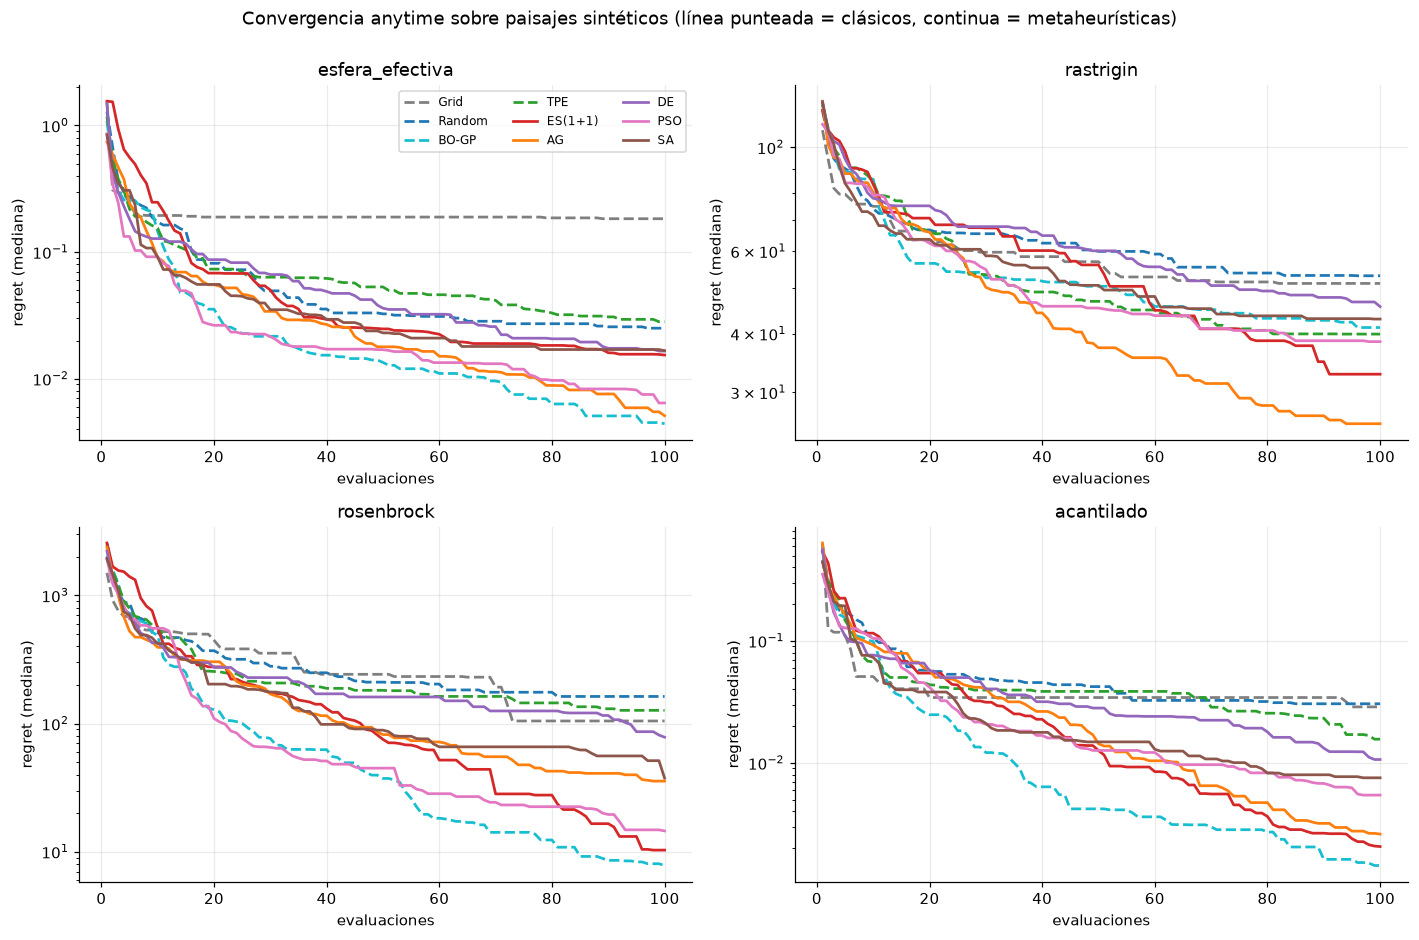

In [10]:
def curvas_mediana(df, tarea, ref=0.0):
    out = {}
    for a in ALGOS:
        C = np.array(df[(df.tarea == tarea) & (df.alg == a)]["curva"].tolist()) - ref
        out[a] = (np.median(C, 0), np.percentile(C, 25, 0), np.percentile(C, 75, 0))
    return out


fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (nombre, (f, ref)) in zip(axes.ravel(), FUNCIONES.items()):
    cur = curvas_mediana(dfA, nombre, ref)
    for a in ALGOS:
        med = np.maximum(cur[a][0], 1e-6)
        ax.plot(np.arange(1, B_A + 1), med, ESTILO[a], color=COLOR[a], lw=1.8, label=a)
    ax.set_yscale("log"); ax.set_title(nombre); ax.set_xlabel("evaluaciones"); ax.set_ylabel("regret (mediana)")
axes[0, 0].legend(ncol=3, fontsize=8)
plt.suptitle("Convergencia anytime sobre paisajes sintéticos (línea punteada = clásicos, continua = metaheurísticas)", y=1.0)
plt.tight_layout(); plt.show()

**Lectura de las curvas** (mediana de 30 semillas, eje vertical logarítmico):

- **Grid** se queda plano muy pronto en `esfera_efectiva`: con 6 dimensiones y 100 puntos solo cabe una malla de 3 niveles por eje, y lo que no está en la malla no se explora. En las demás funciones va por debajo de Random Search o a su altura.
- **Random Search** baja despacio y de forma casi lineal en escala log: cada punto nuevo tiene poca probabilidad de mejorar el mejor visto.
- **BO-GP** arranca igual que Random (su diseño inicial son 10 puntos aleatorios), pero a partir de ahí baja con claridad más rápido en `esfera_efectiva`, `rosenbrock` y `acantilado`. En `rastrigin`, con muchos óptimos locales, su ventaja sobre Random es pequeña.
- **AG** se separa del resto en `rastrigin` a partir de unas 40 evaluaciones y acaba claramente primero. **PSO** es muy competitivo al principio en `esfera_efectiva` y `rosenbrock`, y luego pierde ritmo.
- **ES (1+1)** empieza lenta (arranca de un solo punto) y mejora de forma sostenida hasta el final.
- **DE** y **TPE** quedan por detrás de los demás métodos adaptativos y cerca de Random en `esfera_efectiva` y `rastrigin`; DE mejora algo al final en `rosenbrock` y `acantilado`.

### 6.2 Resultado final: tabla, rangos y significancia

Para cada función se calcula el regret medio a $B=100$, y para cada método se cuenta contra **Random Search**, con una prueba de Mann–Whitney (las semillas son independientes) corregida por Holm dentro de cada función:

- *mejor*: significativamente menor que Random ($p_{\text{Holm}}<0.05$).
- *peor*: significativamente mayor.
- *igual*: sin diferencia significativa.

In [11]:
def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p)
    aj = np.empty(m); run = 0.0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); aj[i] = min(run, 1.0)
    return aj


def tabla_resumen(df, col, tareas):
    media = df.pivot_table(index="alg", columns="tarea", values=col, aggfunc="mean").loc[list(ALGOS), tareas]
    mediana = df.pivot_table(index="alg", columns="tarea", values=col, aggfunc="median").loc[list(ALGOS), tareas]
    rangos = media.rank(axis=0, method="average")
    veredictos = {}
    for t in tareas:
        base = df[(df.tarea == t) & (df.alg == "Random")][col].values
        otros = [a for a in ALGOS if a != "Random"]
        p = [stats.mannwhitneyu(df[(df.tarea == t) & (df.alg == a)][col].values, base, alternative="two-sided").pvalue
             for a in otros]
        pa = holm(p)
        for a, pv in zip(otros, pa):
            m_a = df[(df.tarea == t) & (df.alg == a)][col].median(); m_r = np.median(base)
            veredictos[(a, t)] = "mejor" if (pv < 0.05 and m_a < m_r) else ("peor" if (pv < 0.05 and m_a > m_r) else "igual")
    return media, mediana, rangos, veredictos


tareasA = list(FUNCIONES)
mediaA, medianaA, rangosA, vereA = tabla_resumen(dfA, "regret", tareasA)
print("Regret medio a B=100 (30 semillas)")
display_df = mediaA.copy()
display_df.columns = [c for c in display_df.columns]
print(display_df.map(lambda v: f"{v:.3g}").to_string())
print()
print("Rango promedio por función (1 = mejor):")
print(rangosA.round(1).assign(**{"rango medio": rangosA.mean(1).round(2)}).to_string())
print()
cuenta = pd.DataFrame({a: {"mejor que Random": sum(vereA[(a, t)] == "mejor" for t in tareasA),
                           "igual": sum(vereA[(a, t)] == "igual" for t in tareasA),
                           "peor que Random": sum(vereA[(a, t)] == "peor" for t in tareasA)}
                       for a in ALGOS if a != "Random"}).T
print("Mann-Whitney vs Random (Holm), sobre las 4 funciones:")
print(cuenta.to_string())

Regret medio a B=100 (30 semillas)
        esfera_efectiva rastrigin rosenbrock acantilado
alg                                                    
Grid              0.186      52.7        162     0.0316
Random           0.0262      52.6        170     0.0284
BO-GP           0.00526      39.8       9.39    0.00262
TPE              0.0579      36.8        168     0.0236
ES(1+1)          0.0138      41.3       21.8    0.00529
AG              0.00737      26.3       44.2    0.00493
DE               0.0167      43.7       89.8     0.0127
PSO             0.00878      35.3       18.9    0.00699
SA               0.0173      42.1       55.2    0.00866

Rango promedio por función (1 = mejor):
tarea    esfera_efectiva  rastrigin  rosenbrock  acantilado  rango medio
alg                                                                     
Grid                 9.0        9.0         7.0         9.0         8.50
Random               7.0        8.0         9.0         8.0         8.00
BO-GP           

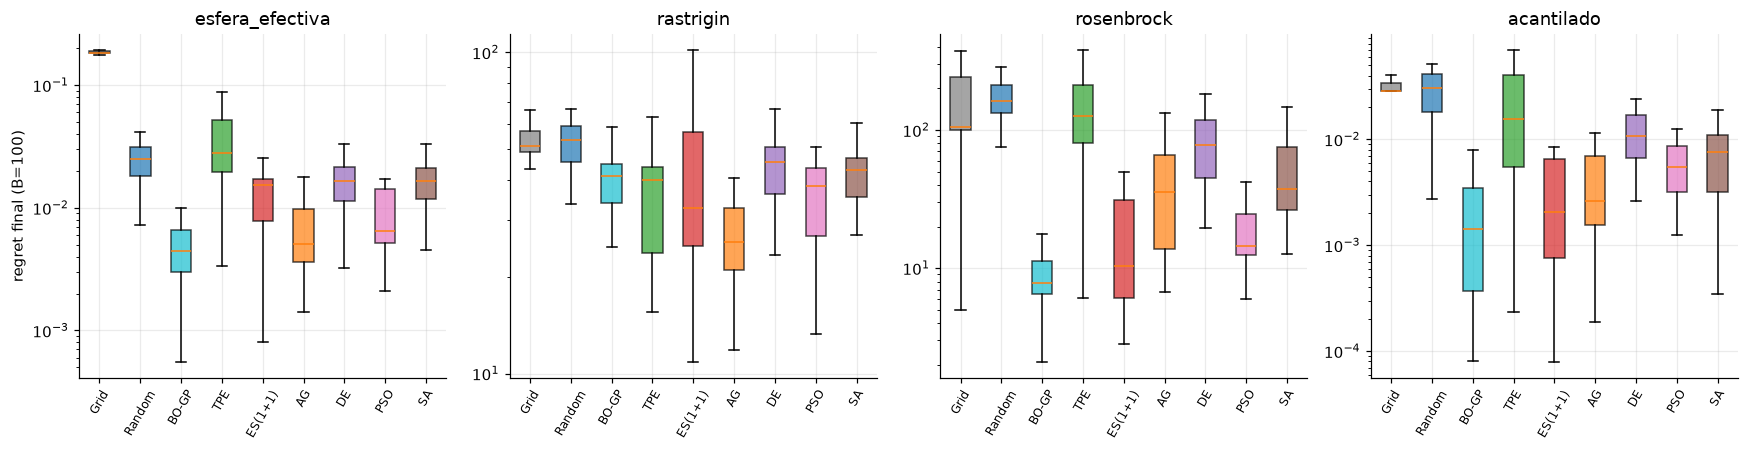

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, t in zip(axes, tareasA):
    datos = [np.maximum(dfA[(dfA.tarea == t) & (dfA.alg == a)]["regret"].values, 1e-6) for a in ALGOS]
    bp = ax.boxplot(datos, patch_artist=True, showfliers=False)
    for patch, a in zip(bp["boxes"], ALGOS):
        patch.set_facecolor(COLOR[a]); patch.set_alpha(0.7)
    ax.set_xticklabels(list(ALGOS), rotation=60, fontsize=8); ax.set_yscale("log"); ax.set_title(t)
axes[0].set_ylabel("regret final (B=100)")
plt.tight_layout(); plt.show()

**Lectura de la tabla y de las pruebas** (30 semillas, $B=100$):

- **BO-GP y las cinco metaheurísticas mejoran de forma significativa a Random Search en las cuatro funciones** (después de la corrección de Holm). Grid no mejora a Random en ninguna, y en una función incluso es peor. TPE solo mejora a Random en una de las cuatro.
- **BO-GP tiene el mejor rango en tres de las cuatro funciones** (`esfera_efectiva`, `rosenbrock` y `acantilado`): son suaves y de solo 6 dimensiones, justo lo que el GP supone. En `rosenbrock` (valle estrecho y curvo) su regret medio queda muy por debajo del de Random y Grid.
- **En `rastrigin` (muchos óptimos locales) gana el AG**, seguido de PSO y TPE. El GP, que supone una superficie suave y global, aquí aporta poco: BO-GP queda en la cuarta posición.
- **TPE decepciona en las funciones suaves.** Es esperable: modela cada dimensión por separado e ignora interacciones (como el producto $u_2u_3$ de `acantilado` o la curvatura de `rosenbrock`), y con solo 100 evaluaciones tiene poco material para sus densidades. Tampoco se le ajustaron $\gamma$ ni el número de candidatos: es un resultado de *esta* implementación sin ajustar, no un veredicto sobre Optuna u Hyperopt.
- **DE queda a mitad de tabla** porque con $B=100$ y población 12 solo da unas 8 generaciones. DE necesita más generaciones para cumplir lo que promete.
- **Grid y Random quedan empatados al final de la tabla** (rangos medios 8.5 y 8.0): con 6 dimensiones y 100 evaluaciones, la malla no aporta nada sobre el muestreo aleatorio.

### 6.3 ¿Quién gana según el presupuesto?

Una comparación a un solo presupuesto puede engañar. Aquí se calcula el **rango promedio** (1 = mejor) sobre las cuatro funciones usando la mediana del regret en cada punto de la curva.

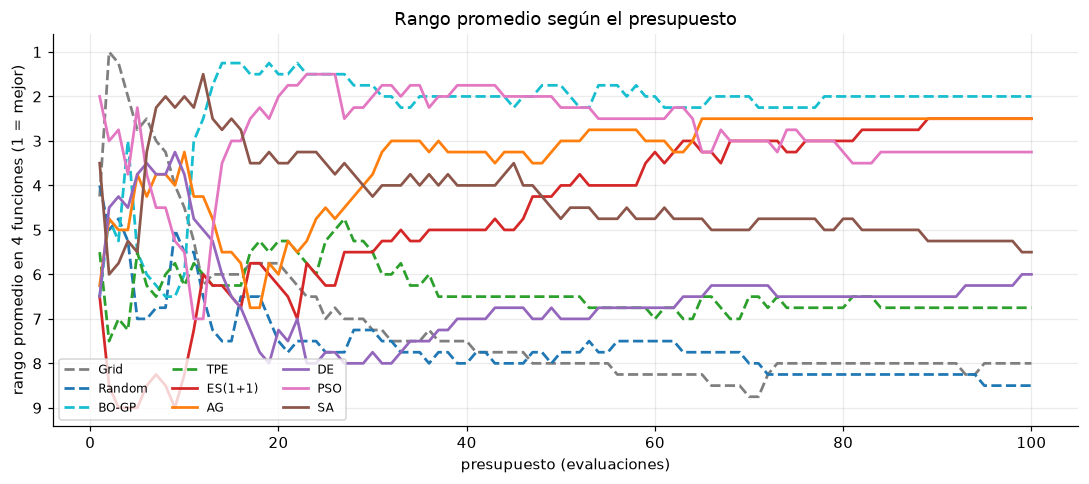

         10   20   40   70   100
Grid     4.5  5.8  7.5  8.8  8.0
Random   5.5  7.5  8.0  8.0  8.5
BO-GP    6.0  1.5  2.0  2.0  2.0
TPE      6.2  5.2  6.5  6.5  6.8
ES(1+1)  8.2  6.2  5.0  3.0  2.5
AG       3.2  6.0  3.2  2.5  2.5
DE       3.8  7.2  7.0  6.2  6.0
PSO      5.5  2.0  1.8  3.0  3.2
SA       2.0  3.5  4.0  5.0  5.5


In [13]:
def rangos_por_presupuesto(df, tareas, B):
    pts = np.arange(1, B + 1)
    R = np.zeros((len(ALGOS), len(pts)))
    for t in tareas:
        ref = TAREAS[t].get("ref") or 0.0
        med = np.array([np.median(np.array(df[(df.tarea == t) & (df.alg == a)]["curva"].tolist()) - ref, 0) for a in ALGOS])
        R += pd.DataFrame(med).rank(axis=0).values
    return pd.DataFrame(R / len(tareas), index=list(ALGOS), columns=pts)


RP = rangos_por_presupuesto(dfA, tareasA, B_A)
fig, ax = plt.subplots(figsize=(10, 4.5))
for a in ALGOS:
    ax.plot(RP.columns, RP.loc[a], ESTILO[a], color=COLOR[a], lw=1.8, label=a)
ax.set_xlabel("presupuesto (evaluaciones)"); ax.set_ylabel("rango promedio en 4 funciones (1 = mejor)")
ax.invert_yaxis(); ax.legend(ncol=3, fontsize=8); ax.set_title("Rango promedio según el presupuesto")
plt.tight_layout(); plt.show()
print(RP[[10, 20, 40, 70, 100]].round(1).to_string())

**El orden depende del presupuesto.** La gráfica es ruidosa en las primeras evaluaciones, porque todos los métodos parten de muestras aleatorias y las diferencias son pequeñas; a partir de unas 30 evaluaciones se estabiliza.

- **Con ≈10 evaluaciones o menos**, SA, AG y DE llevan ventaja: empiezan a explotar enseguida, mientras que BO-GP sigue en su diseño inicial de 10 puntos aleatorios y todavía no tiene modelo.
- **De 20 a 100 evaluaciones, BO-GP es el mejor o el segundo mejor** (rango medio ≈ 2). PSO es muy bueno entre 20 y 40 evaluaciones y luego cede terreno a medida que AG y ES (1+1) mejoran.
- **ES (1+1) y AG ganan posiciones con el presupuesto**: empiezan mal (ES (1+1) es de las últimas con ≈10 evaluaciones) y a $B=100$ comparten con BO-GP los primeros puestos (rangos entre 2.0 y 2.5).
- **SA empeora relativamente** (rango ≈ 2 al principio, ≈ 5.5 al final). Es coherente con su diseño: el enfriamiento depende de $B$, y al cerrar se comporta casi como una búsqueda local con poca diversidad.
- **Random y Grid empeoran su rango a medida que crece el presupuesto**, porque los demás métodos aprovechan mejor cada evaluación adicional.

Moraleja: una tabla a un solo presupuesto puede cambiar de ganador al cambiar $B$. Elige el presupuesto que realmente tendrás.

## 7. Experimento B: efecto de la dimensión del espacio

Aquí se varía $d\in\{2,4,8,16\}$ con $B=100$ fijo, sobre dos funciones que contrastan la **dimensión efectiva**:

- **`esfera_d`**: 2 ejes dominan la pérdida; los demás pesan 100 veces menos (0.05 frente a 5) pero **no son nulos**. Como el regret incluye ese término, cuantos más ejes menores haya, más regret "piso" suma una configuración sin afinar (unos $0.004$ por eje en promedio con puntos aleatorios).
- **`rastrigin_d`**: *todos* los ejes importan por igual y hay muchos óptimos locales (alta dimensión efectiva).

Qué dice la teoría que habría que esperar:

- **Grid** pierde cuando crece $d$: caben menos niveles por eje.
- **Bayesiana con GP** degrada cuando todas las dimensiones importan: hacen falta exponencialmente más puntos para cubrir el espacio.
- Si solo unos pocos ejes dominan, **Random Search** explora bien esos ejes sin importar cuántos otros haya (Bergstra & Bengio, 2012). Aquí hay que leer los resultados con cuidado por el piso mencionado arriba.

1080 corridas en 9 s


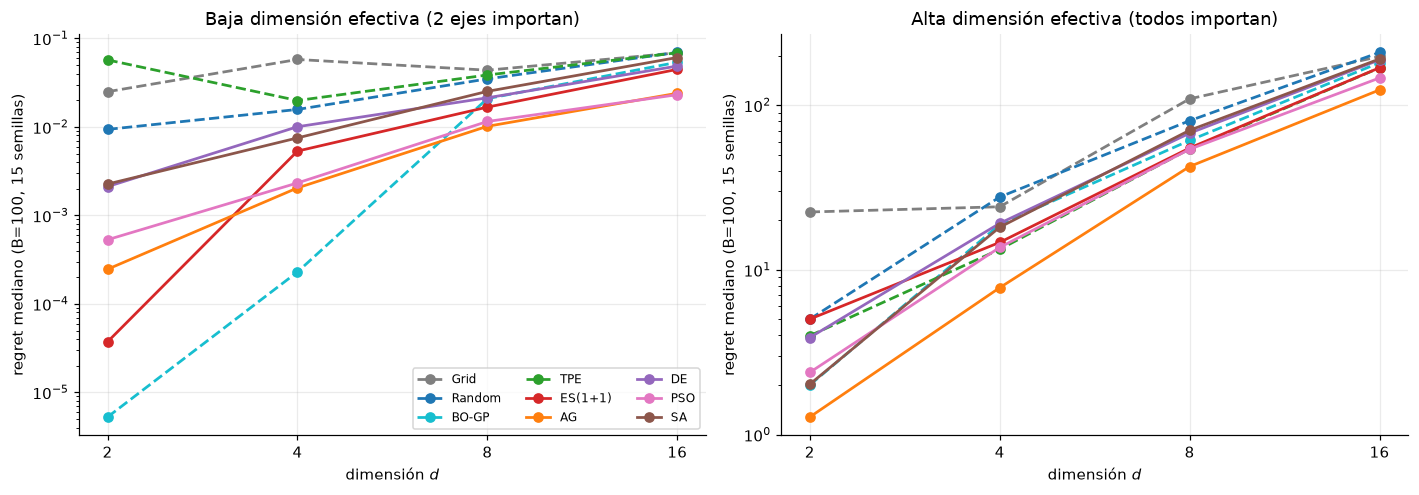

tarea   esfera_d2 esfera_d4 esfera_d8 esfera_d16 rastrigin_d2 rastrigin_d4 rastrigin_d8 rastrigin_d16
alg                                                                                                  
Grid        0.025    0.0578    0.0438     0.0688         22.5         24.2          109           198
Random    0.00937    0.0158    0.0349     0.0695         5.02         27.7         80.5           209
BO-GP    5.27e-06  0.000229    0.0209     0.0538            2         18.9         61.1           181
TPE        0.0572    0.0199    0.0386     0.0688         3.98         13.3         54.3           169
ES(1+1)  3.73e-05   0.00533    0.0167     0.0447         5.03         14.7           55           169
AG       0.000246   0.00205    0.0102      0.024         1.28          7.8         42.4           124
DE        0.00212      0.01    0.0213     0.0487         3.88         19.2         67.6           189
PSO      0.000531   0.00233    0.0115     0.0231         2.39         13.7        

In [14]:
def esfera_d(u):
    return 5 * ((u[0] - 0.3) ** 2 + (u[1] - 0.7) ** 2) + 0.05 * ((u[2:] - 0.5) ** 2).sum()


def rastrigin_d(u):
    rng_o = np.random.default_rng(99)
    z = (10.24 * u - 5.12) - rng_o.uniform(-3, 3, len(u))   # óptimo fijo para cada d (semilla fija)
    return 10 * len(z) + (z ** 2 - 10 * np.cos(2 * np.pi * z)).sum()


DIMS = [2, 4, 8, 16]
for d in DIMS:
    TAREAS[f"esfera_d{d}"] = dict(f=esfera_d, d=d, ref=0.0)
    TAREAS[f"rastrigin_d{d}"] = dict(f=rastrigin_d, d=d, ref=0.0)
assert abs(rastrigin_d((np.random.default_rng(99).uniform(-3, 3, 8) + 5.12) / 10.24)) < 1e-9

t0 = time.time()
tareas_B = [f"{p}_d{d}" for p in ("esfera", "rastrigin") for d in DIMS]
res_B = correr_lote(tareas_B, list(ALGOS), range(15), B=100)
dfB = pd.DataFrame(res_B); dfB["regret"] = dfB["mejor"]
print(f"{len(dfB)} corridas en {time.time()-t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for ax, pref, titulo in zip(axes, ("esfera", "rastrigin"), ("Baja dimensión efectiva (2 ejes importan)", "Alta dimensión efectiva (todos importan)")):
    for a in ALGOS:
        med = [np.median(dfB[(dfB.tarea == f"{pref}_d{d}") & (dfB.alg == a)]["regret"]) for d in DIMS]
        ax.plot(DIMS, np.maximum(med, 1e-6), "o" + ESTILO[a], color=COLOR[a], lw=1.8, label=a)
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(DIMS); ax.set_xticklabels(DIMS)
    ax.set_xlabel("dimensión $d$"); ax.set_ylabel("regret mediano (B=100, 15 semillas)"); ax.set_title(titulo)
axes[0].legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

piv = dfB.pivot_table(index="alg", columns="tarea", values="regret", aggfunc="median").loc[list(ALGOS), tareas_B]
print(piv.map(lambda v: f"{v:.3g}").to_string())

**Qué muestra el barrido de la dimensión** (regret mediano, $B=100$, 15 semillas):

- **Baja dimensión efectiva (`esfera_d`).**
  - Con $d=2$ y $d=4$, **BO-GP es el mejor con diferencia**: su regret ($\approx 5\times10^{-6}$ y $2\times10^{-4}$) está órdenes de magnitud por debajo del de Random ($\approx 9\times10^{-3}$ y $2\times10^{-2}$). En $d=2$, ES (1+1) es la segunda.
  - **A partir de $d=8$ el GP pierde su ventaja** y AG y PSO lo superan (en $d=16$, regret ≈ 0.023–0.024 frente a ≈ 0.054 de BO-GP y ≈ 0.070 de Random).
  - **Grid es peor que Random** hasta $d=8$. Con $d=16$ ambos coinciden: con 2 niveles por eje, evaluar una muestra aleatoria de 100 puntos de la malla $2^{16}$ equivale casi a un muestreo aleatorio.
  - **TPE** es peor que Random con $d=2$ y $d=4$ (con pocas dimensiones tiene poco que modelar).
  - Un matiz: los ejes "menores" pesan poco pero no son nulos, así que parte del regret que crece con $d$ se debe a los 14 términos pequeños que los métodos que sí los afinan (AG, PSO) reducen. No es una evidencia limpia de la tesis de Bergstra & Bengio; para ello habría que usar ejes realmente irrelevantes.
- **Alta dimensión efectiva (`rastrigin_d`).**
  - **AG gana en todas las dimensiones.** En $d=16$ su regret (≈ 124) es ≈ 40 % menor que el de Random (≈ 209).
  - **BO-GP mejora a Random pero muy poco en $d=16$** (≈ 181 frente a ≈ 209, alrededor de un 13 % de mejora), y nunca gana. Es la degradación con la dimensión que predice la teoría.
  - Todos los métodos empeoran mucho al crecer $d$ (el regret de Random pasa de ≈ 5 a ≈ 209) y las diferencias relativas se comprimen: con un presupuesto fijo, un espacio de 16 dimensiones multimodal no se puede explorar bien con ningún método.

Resumen: **BO-GP es el campeón en pocas dimensiones y paisaje suave; las poblaciones (AG, PSO) aguantan mejor al subir $d$ o cuando el paisaje es rugoso.**

## 8. Experimento C: tres tareas reales de ML

Ahora, modelos reales de scikit-learn sobre conjuntos de datos incluidos en la librería (o generados con semilla), sin descargas:

| Tarea | Modelo | Datos | Espacio ($d$) | Pérdida (CV, 3 pliegues) |
|---|---|---|---|---|
| `svm_digits` | SVM (kernel `rbf`/`poly`/`sigmoid`) | dígitos manuscritos, 900 muestras | 4: $C$ (log), $\gamma$ (log), kernel (cat.), grado (int, solo usado con `poly`) | error de clasificación |
| `hgb_clasif` | `HistGradientBoostingClassifier` | clasificación sintética con ruido de etiquetas (1 500 muestras, 20 variables) | 6: tasa de aprendizaje (log), iteraciones, hojas, mín. muestras por hoja, $L_2$ (log), profundidad | log-loss |
| `mlp_diabetes` | `MLPRegressor` | diabetes (442 muestras) | 5: capas, unidades, activación (cat.), $\alpha$ (log), tasa de aprendizaje (log) | RMSE (objetivo estandarizado) |

Reglas:

- Cada configuración se evalúa con **validación cruzada de 3 pliegues sobre el 75 % de entrenamiento**. Los pliegues y la semilla del modelo son fijos, así que la pérdida es **determinista**: lo que varía entre corridas es solo el optimizador.
- El 25 % restante es un **conjunto de prueba que ningún optimizador ve**. Se usa al final para medir cuánto se sobreajusta la selección a la validación cruzada.
- La caché se hace por **configuración decodificada** (`Espacio.clave`), de modo que dos puntos del cubo que dan el mismo modelo no gastan evaluaciones.
- Presupuesto $B=40$ evaluaciones, 6 semillas por método.
- El MLP se entrena con `max_iter=200`: algunas configuraciones (tasas de aprendizaje muy bajas) no llegan a converger. Eso forma parte del paisaje que el optimizador ve.

Los espacios son deliberadamente **mixtos y condicionales** (el grado del polinomio no afecta a `rbf`), como en la práctica.

In [15]:
from sklearn.datasets import load_digits, load_diabetes, make_classification
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, log_loss, mean_squared_error
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def _partir(X, y, estrat):
    return train_test_split(X, y, test_size=0.25, random_state=0, stratify=y if estrat else None)


# ---------- Tarea 1: SVM sobre dígitos
Xd, yd = load_digits(return_X_y=True)
sel = np.random.default_rng(0).choice(len(yd), 900, replace=False)
Xtr1, Xte1, ytr1, yte1 = _partir(Xd[sel], yd[sel], True)
ESP1 = Espacio([("C", "log", 1e-2, 1e3), ("gamma", "log", 1e-5, 1e1),
                ("kernel", "cat", ["rbf", "poly", "sigmoid"]), ("degree", "int", 2, 5)])
CV1 = StratifiedKFold(3, shuffle=True, random_state=0)


def modelo1(c):
    return make_pipeline(StandardScaler(), SVC(C=c["C"], gamma=c["gamma"], kernel=c["kernel"],
                                               degree=c["degree"], coef0=1.0))


def perdida1(u):
    return 1.0 - cross_val_score(modelo1(ESP1.decodificar(u)), Xtr1, ytr1, cv=CV1).mean()


def prueba1(u):
    return 1.0 - accuracy_score(yte1, modelo1(ESP1.decodificar(u)).fit(Xtr1, ytr1).predict(Xte1))


# ---------- Tarea 2: Gradient Boosting sobre clasificación sintética con ruido
Xc, yc = make_classification(1500, 20, n_informative=6, n_redundant=4, flip_y=0.1, class_sep=0.8, random_state=0)
Xtr2, Xte2, ytr2, yte2 = _partir(Xc, yc, True)
ESP2 = Espacio([("learning_rate", "log", 1e-3, 0.5), ("max_iter", "int", 20, 150), ("max_leaf_nodes", "int", 4, 64),
                ("min_samples_leaf", "int", 5, 100), ("l2", "log", 1e-6, 10.0), ("max_depth", "int", 2, 10)])
CV2 = StratifiedKFold(3, shuffle=True, random_state=0)


def modelo2(c):
    return HistGradientBoostingClassifier(learning_rate=c["learning_rate"], max_iter=c["max_iter"],
                                          max_leaf_nodes=c["max_leaf_nodes"], min_samples_leaf=c["min_samples_leaf"],
                                          l2_regularization=c["l2"], max_depth=c["max_depth"],
                                          early_stopping=False, random_state=0)


def perdida2(u):
    return -cross_val_score(modelo2(ESP2.decodificar(u)), Xtr2, ytr2, cv=CV2, scoring="neg_log_loss").mean()


def prueba2(u):
    m = modelo2(ESP2.decodificar(u)).fit(Xtr2, ytr2)
    return log_loss(yte2, m.predict_proba(Xte2))


# ---------- Tarea 3: MLP sobre diabetes
Xb, yb = load_diabetes(return_X_y=True); yb = (yb - yb.mean()) / yb.std()
Xtr3, Xte3, ytr3, yte3 = _partir(Xb, yb, False)
ESP3 = Espacio([("capas", "int", 1, 3), ("unidades", "int", 8, 128), ("activacion", "cat", ["relu", "tanh"]),
                ("alpha", "log", 1e-6, 1.0), ("lr", "log", 1e-4, 1e-1)])
CV3 = KFold(3, shuffle=True, random_state=0)


def modelo3(c):
    return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(c["unidades"],) * c["capas"],
                                                        activation=c["activacion"], alpha=c["alpha"],
                                                        learning_rate_init=c["lr"], max_iter=200, random_state=0))


def perdida3(u):
    return -cross_val_score(modelo3(ESP3.decodificar(u)), Xtr3, ytr3, cv=CV3, scoring="neg_root_mean_squared_error").mean()


def prueba3(u):
    return float(np.sqrt(mean_squared_error(yte3, modelo3(ESP3.decodificar(u)).fit(Xtr3, ytr3).predict(Xte3))))


REAL = {"svm_digits": (ESP1, perdida1, prueba1), "hgb_clasif": (ESP2, perdida2, prueba2),
        "mlp_diabetes": (ESP3, perdida3, prueba3)}
for nombre, (esp, f, _) in REAL.items():
    TAREAS[nombre] = dict(f=f, d=esp.d, clave=esp.clave, ref=None)

# Costo de una evaluación y pérdida de la configuración central
for nombre, (esp, f, _) in REAL.items():
    t0 = time.perf_counter(); v = f(np.full(esp.d, 0.5)); dt = time.perf_counter() - t0
    aleat = [f(np.random.default_rng(s).random(esp.d)) for s in range(12)]
    print(f"{nombre:13s} d={esp.d} | config central: pérdida {v:.3f} ({dt*1000:.0f} ms) | "
          f"12 configs aleatorias: mediana {np.median(aleat):.3f}, rango [{min(aleat):.3f}, {max(aleat):.3f}]")

svm_digits    d=4 | config central: pérdida 0.022 (17 ms) | 12 configs aleatorias: mediana 0.219, rango [0.040, 0.892]


hgb_clasif    d=6 | config central: pérdida 0.483 (103 ms) | 12 configs aleatorias: mediana 0.502, rango [0.428, 0.671]


mlp_diabetes  d=5 | config central: pérdida 0.753 (96 ms) | 12 configs aleatorias: mediana 0.814, rango [0.701, 0.860]


In [16]:
B_C, SEM_C = 40, 6
t0 = time.time()
res_C = correr_lote(list(REAL), list(ALGOS), range(SEM_C), B_C)
dfC = pd.DataFrame(res_C); dfC["regret"] = dfC["mejor"]
print(f"{len(dfC)} corridas ({len(ALGOS)} métodos x {len(REAL)} tareas x {SEM_C} semillas, B={B_C}) en {time.time()-t0:.0f} s")
print("evaluaciones realmente gastadas (mín/máx):", dfC["n"].min(), dfC["n"].max())

162 corridas (9 métodos x 3 tareas x 6 semillas, B=40) en 93 s
evaluaciones realmente gastadas (mín/máx): 31 40


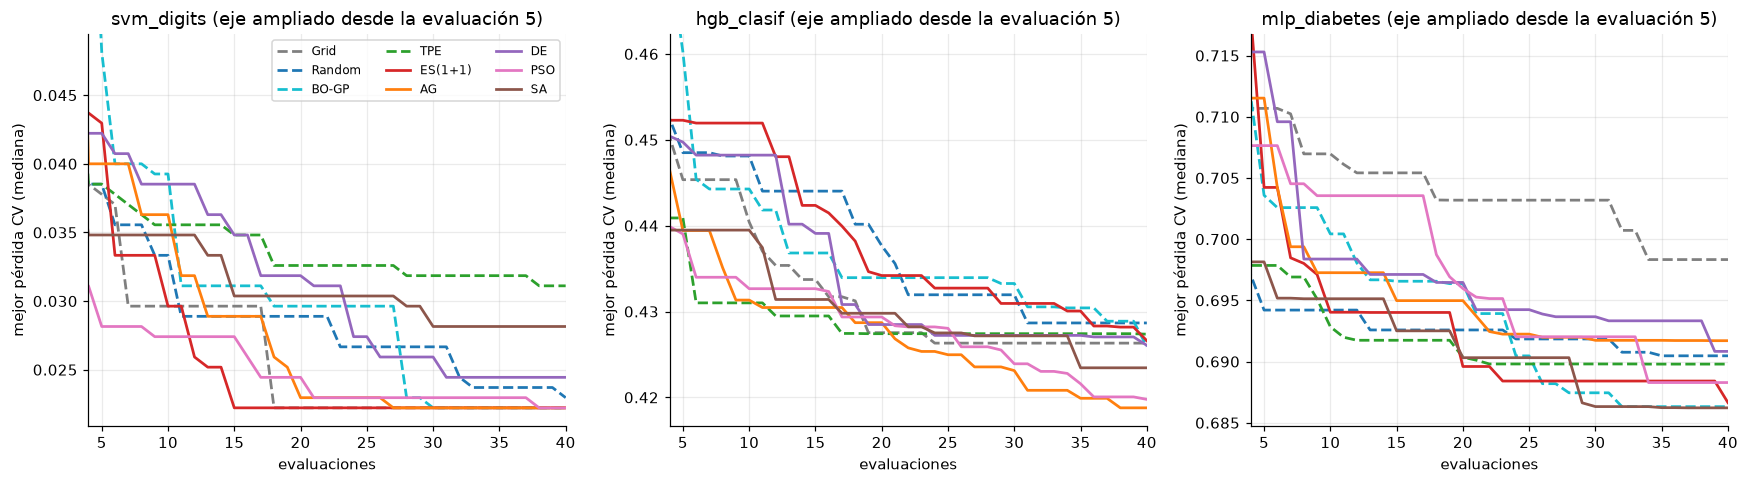

Pérdida CV final (media ± desv., 6 semillas, B=40; menor es mejor)
              svm_digits       hgb_clasif     mlp_diabetes
Grid     0.0222 ± 0.0000  0.4273 ± 0.0015  0.6983 ± 0.0018
Random   0.0247 ± 0.0064  0.4294 ± 0.0066  0.6892 ± 0.0042
BO-GP    0.0264 ± 0.0078  0.4280 ± 0.0087  0.6884 ± 0.0062
TPE      0.0304 ± 0.0056  0.4272 ± 0.0092  0.6909 ± 0.0066
ES(1+1)  0.0235 ± 0.0069  0.4290 ± 0.0064  0.6879 ± 0.0064
AG       0.0230 ± 0.0028  0.4190 ± 0.0033  0.6899 ± 0.0072
DE       0.0252 ± 0.0019  0.4252 ± 0.0035  0.6935 ± 0.0062
PSO      0.0227 ± 0.0008  0.4210 ± 0.0042  0.6903 ± 0.0061
SA       0.0284 ± 0.0076  0.4269 ± 0.0106  0.6859 ± 0.0059

Rango promedio por tarea (1 = mejor):
tarea    svm_digits  hgb_clasif  mlp_diabetes  rango medio
alg                                                       
Grid            1.0         6.0           9.0         5.33
Random          5.0         9.0           4.0         6.00
BO-GP           7.0         7.0           3.0         5.67
TPE      

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, nombre in zip(axes, REAL):
    meds = {}
    for a in ALGOS:
        C = np.array(dfC[(dfC.tarea == nombre) & (dfC.alg == a)]["curva"].tolist())
        meds[a] = np.median(C, 0)
        ax.plot(np.arange(1, B_C + 1), meds[a], ESTILO[a], color=COLOR[a], lw=1.8, label=a)
    # zoom: ignora el tramo inicial (las primeras 4 evaluaciones) para que se vean las diferencias
    arriba = max(m[4] for m in meds.values()); abajo = min(m[-1] for m in meds.values())
    ax.set_ylim(abajo - 0.05 * (arriba - abajo), arriba + 0.05 * (arriba - abajo)); ax.set_xlim(4, B_C)
    ax.set_title(nombre + " (eje ampliado desde la evaluación 5)"); ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor pérdida CV (mediana)")
axes[0].legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

tareasC = list(REAL)
mediaC, medianaC, rangosC, vereC = tabla_resumen(dfC, "regret", tareasC)
dsC = dfC.groupby(["tarea", "alg"])["regret"].agg(["mean", "std"])
print("Pérdida CV final (media ± desv., 6 semillas, B=40; menor es mejor)")
filas = {a: {t: f"{dsC.loc[(t, a), 'mean']:.4f} ± {dsC.loc[(t, a), 'std']:.4f}" for t in tareasC} for a in ALGOS}
print(pd.DataFrame(filas).T.to_string())
print()
print("Rango promedio por tarea (1 = mejor):")
print(rangosC.round(1).assign(**{"rango medio": rangosC.mean(1).round(2)}).to_string())
print()
cuentaC = pd.DataFrame({a: {"mejor que Random": sum(vereC[(a, t)] == "mejor" for t in tareasC),
                            "igual": sum(vereC[(a, t)] == "igual" for t in tareasC),
                            "peor que Random": sum(vereC[(a, t)] == "peor" for t in tareasC)}
                        for a in ALGOS if a != "Random"}).T
print("Mann-Whitney vs Random (Holm), sobre las 3 tareas:")
print(cuentaC.to_string())

**Lectura de las tareas reales** (6 semillas, $B=40$):

- **El resultado es sobrio: tras la corrección de Holm, ningún método supera a Random Search en ninguna de las tres tareas.** Grid es peor que Random en `mlp_diabetes` y no se distingue en las demás.
- **Las diferencias entre métodos son del tamaño de la variación entre semillas.** Por ejemplo, en `mlp_diabetes` las medias van de 0.686 a 0.698 con desviaciones de ≈ 0.006. Con 6 semillas y 3 tareas la potencia estadística es baja: no se puede afirmar que "todos son iguales", solo que *este experimento* no detecta diferencias.
- **Por qué es difícil ganar aquí.** Con $B=40$ y 4–6 dimensiones, muchas configuraciones aleatorias ya son buenas (en `svm_digits`, de 12 configuraciones aleatorias la mejor ya tiene error 0.040, y la mejor encontrada llega a ≈ 0.018). Además la pérdida es casi plana cerca del óptimo, por lo que el margen total de mejora es pequeño.
- **Tendencias, sin pasarse de la raya.** El **AG** y **PSO** obtienen los mejores rangos en `hgb_clasif` (AG ≈ 0.419 frente a Random ≈ 0.429); **SA** y **ES (1+1)** en `mlp_diabetes`; en `svm_digits`, de solo 4 dimensiones, **Grid** obtiene el mejor promedio con desviación nula: una malla de 3 niveles por eje cubre bien un espacio tan pequeño.
- **Las mejores configuraciones** (celda anterior) son razonables: en el SVM, un kernel `rbf` o `poly` de grado 2 con $C$ moderada, y en el GB, tasa de aprendizaje baja con muchas iteraciones.

Esto contrasta con el experimento A: en problemas sintéticos de 6 dimensiones con $B=100$ y 30 semillas las diferencias sí se detectan. La enseñanza práctica es que, **con espacios pequeños, presupuestos cortos y pérdidas planas, la elección del optimizador importa poco**, y Random Search es un punto de partida muy defendible.

### 8.1 Mejores configuraciones encontradas

La mejor configuración de cada tarea sobre todas las corridas, decodificada a hiperparámetros reales.

In [18]:
for nombre, (esp, f, prueba) in REAL.items():
    sub = dfC[dfC.tarea == nombre]
    fila = sub.loc[sub["mejor"].idxmin()]
    print(f"{nombre}: pérdida CV {fila['mejor']:.4f}  (la encontró {fila['alg']}, semilla {fila['semilla']})")
    cfg = esp.decodificar(fila["u"])
    print("   ", {k: (round(v, 5) if isinstance(v, float) else v) for k, v in cfg.items()})

svm_digits: pérdida CV 0.0178  (la encontró ES(1+1), semilla 3)
    {'C': 4.44462, 'gamma': 0.03825, 'kernel': 'poly', 'degree': 2}
hgb_clasif: pérdida CV 0.4145  (la encontró AG, semilla 4)
    {'learning_rate': 0.03282, 'max_iter': 150, 'max_leaf_nodes': 55, 'min_samples_leaf': 5, 'l2': 4e-05, 'max_depth': 5}
mlp_diabetes: pérdida CV 0.6776  (la encontró SA, semilla 0)
    {'capas': 3, 'unidades': 46, 'activacion': 'relu', 'alpha': 1.0, 'lr': 0.00287}


## 9. Resumen global, costo del optimizador y sobreajuste a la validación

### 9.1 Rango promedio sobre los 7 problemas

Se unen las 4 funciones sintéticas y las 3 tareas reales. Para cada problema se ordenan los 9 métodos por pérdida media final y se promedia el rango. Con solo 7 problemas, la prueba de Friedman tiene poca potencia; se reporta como **evidencia exploratoria**, no como veredicto.

Friedman (9 métodos, 7 problemas): chi2 = 24.23, p = 0.0021
         rango medio  mejor rango  peor rango
alg                                          
AG              2.57          1.0         5.0
PSO             3.00          2.0         6.0
BO-GP           3.43          1.0         7.0
ES(1+1)         4.14          2.0         8.0
SA              5.00          1.0         8.0
DE              5.86          3.0         8.0
TPE             6.71          3.0         9.0
Grid            7.14          1.0         9.0
Random          7.14          4.0         9.0


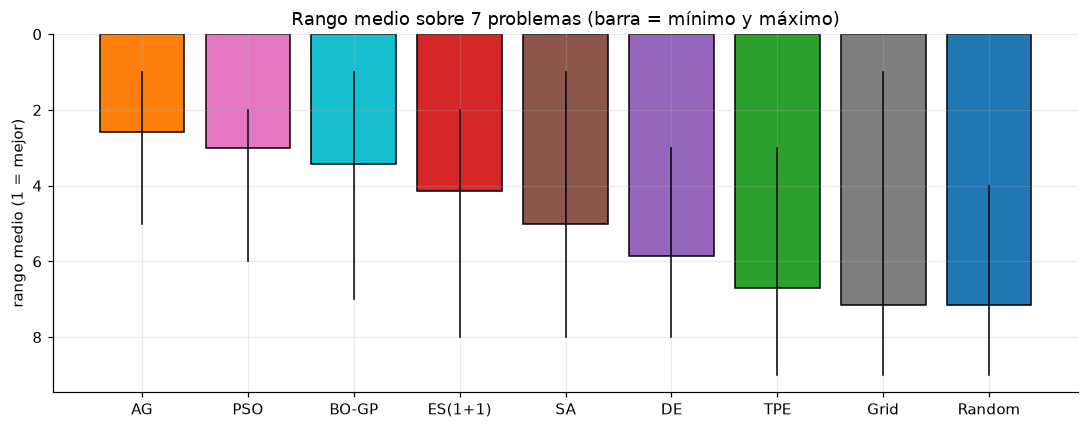

In [19]:
rangos_todos = pd.concat([rangosA, rangosC], axis=1)
resumen = pd.DataFrame({"rango medio": rangos_todos.mean(1), "mejor rango": rangos_todos.min(1),
                        "peor rango": rangos_todos.max(1)}).sort_values("rango medio")
stat, pval = stats.friedmanchisquare(*[rangos_todos.loc[a].values for a in ALGOS])
print(f"Friedman (9 métodos, 7 problemas): chi2 = {stat:.2f}, p = {pval:.4f}")
print(resumen.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
orden = resumen.index
ax.bar(orden, resumen["rango medio"], color=[COLOR[a] for a in orden], edgecolor="k")
for i, a in enumerate(orden):
    ax.plot([i, i], [resumen.loc[a, "mejor rango"], resumen.loc[a, "peor rango"]], "k-", lw=1)
ax.set_ylabel("rango medio (1 = mejor)"); ax.set_title("Rango medio sobre 7 problemas (barra = mínimo y máximo)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Lectura del ranking global.**

- La prueba de Friedman rechaza que los 9 métodos sean equivalentes ($p\approx 0.002$), pero **la señal viene sobre todo de las funciones sintéticas**, donde Grid y Random quedan últimos. En las tareas reales las diferencias fueron pequeñas.
- **AG, PSO y BO-GP encabezan el ranking** (rangos medios ≈ 2.6, 3.0 y 3.4); Grid y Random cierran (≈ 7.1). Entre ellos las diferencias son modestas y el ranking con solo 7 problemas es inestable: un problema más podría reordenar los primeros puestos.
- **Condicionantes.** Las funciones sintéticas son de 6 dimensiones y se evaluaron con $B=100$, un régimen favorable a BO-GP. AG y PSO usan parámetros por defecto sin ajustar, y TPE, DE y SA tampoco se ajustaron: otras configuraciones podrían cambiar el orden (y la notebook [15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb) muestra cuánto).
- Lo robusto es lo **cualitativo**: los métodos que usan el historial de evaluaciones (BO, poblaciones, ES) le ganan a Grid y a Random cuando el paisaje tiene estructura, y esa ventaja desaparece cuando la pérdida es plana y el presupuesto es corto.

### 9.2 Costo propio del optimizador

Cuando evaluar $f$ cuesta milisegundos el propio optimizador puede ser el cuello de botella. Se mide el tiempo **fuera de la evaluación** por iteración, sobre las funciones sintéticas (donde evaluar $f$ es casi gratis), y se compara con el tiempo de evaluar los modelos reales.

*(Los tiempos se midieron con varios procesos en paralelo, así que son órdenes de magnitud, no valores exactos.)*

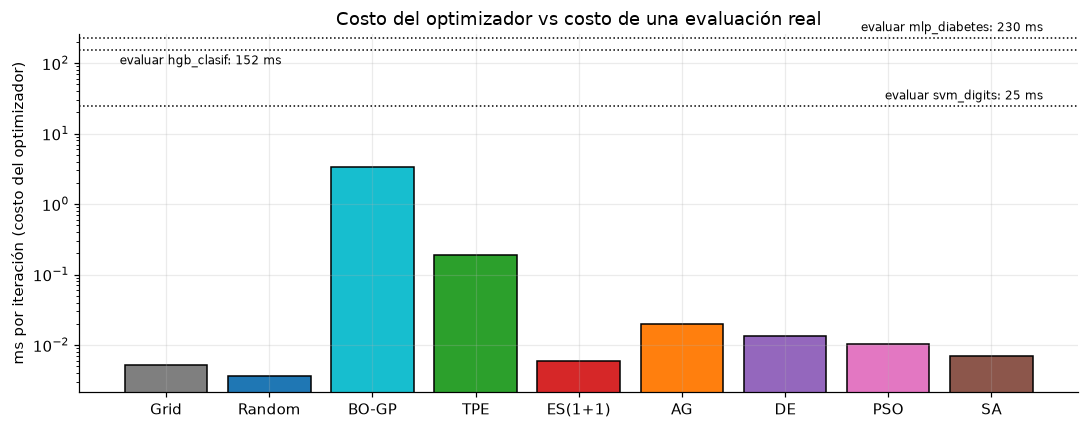

alg
Grid       0.005
Random     0.004
BO-GP      3.310
TPE        0.190
ES(1+1)    0.006
AG         0.020
DE         0.013
PSO        0.010
SA         0.007
{'svm_digits': np.float64(24.7), 'hgb_clasif': np.float64(151.6), 'mlp_diabetes': np.float64(229.9)} (ms por evaluación)


In [20]:
dfA["ovh_ms"] = (dfA["t_total"] - dfA["t_eval"]) / dfA["n"] * 1000
ovh = dfA.groupby("alg")["ovh_ms"].median().loc[list(ALGOS)]
t_ev = {n: dfC[dfC.tarea == n]["t_eval"].sum() / dfC[dfC.tarea == n]["n"].sum() * 1000 for n in REAL}

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(ovh.index, np.maximum(ovh.values, 1e-4), color=[COLOR[a] for a in ovh.index], edgecolor="k")
ax.set_yscale("log"); ax.set_ylabel("ms por iteración (costo del optimizador)")
for (nombre, v), (xp, ha, va, f) in zip(t_ev.items(), [(len(ovh) - 0.5, "right", "bottom", 1.12), (-0.45, "left", "top", 0.88), (len(ovh) - 0.5, "right", "bottom", 1.12)]):
    ax.axhline(v, color="k", ls=":", lw=1); ax.text(xp, v * f, f"evaluar {nombre}: {v:.0f} ms", ha=ha, va=va, fontsize=8)
ax.set_title("Costo del optimizador vs costo de una evaluación real")
plt.tight_layout(); plt.show()
print(ovh.round(3).to_string())
print({k: round(v, 1) for k, v in t_ev.items()}, "(ms por evaluación)")

**Costo del optimizador.**

- **BO-GP es el único método con un costo propio apreciable**: unos pocos milisegundos por iteración con $n\le 100$ observaciones (el ajuste del GP es $O(n^3)$), frente a centésimas de milisegundo de Grid, Random, ES, AG, DE, PSO y SA. **TPE** es intermedio (décimas de milisegundo).
- Frente a una evaluación real (decenas a cientos de milisegundos aquí) el costo de BO-GP es **del orden del 1 % al 20 %** según la tarea (varía con la carga de la máquina): asumible. Frente a una evaluación de milisegundos (como en el experimento A) sería el cuello de botella.
- En la práctica, con evaluaciones de minutos u horas el costo del optimizador es irrelevante, y lo que cuenta es cuánto aprende de cada evaluación. Pero **con miles de evaluaciones el GP exacto deja de ser viable** (por eso existen GP escalables o TPE).

### 9.3 Sobreajuste a la validación: el mejor modelo en un conjunto que nadie vio

El optimizador selecciona la configuración con menor pérdida de validación cruzada. Ese valor es **optimista**: es el mínimo de muchas estimaciones ruidosas (la *maldición del ganador*). Se reentrena cada mejor configuración con todo el entrenamiento y se mide en el 25 % de prueba que ningún optimizador tocó.

Brecha prueba − CV (media de 6 semillas; positiva = optimismo de la validación)
tarea    hgb_clasif  mlp_diabetes  svm_digits
alg                                          
Grid         0.0071        0.0909     -0.0133
Random       0.0031        0.1028     -0.0136
BO-GP       -0.0026        0.1076     -0.0168
TPE          0.0089        0.0741     -0.0170
ES(1+1)      0.0018        0.1238     -0.0131
AG           0.0174        0.1148     -0.0141
DE           0.0028        0.1225     -0.0156
PSO          0.0107        0.0856     -0.0138
SA           0.0047        0.1366     -0.0173

Pérdida en el conjunto de prueba de la mejor configuración (media ± desv.)
              svm_digits       hgb_clasif     mlp_diabetes
Grid     0.0089 ± 0.0000  0.4344 ± 0.0037  0.7892 ± 0.0417
Random   0.0111 ± 0.0054  0.4325 ± 0.0090  0.7920 ± 0.0472
BO-GP    0.0096 ± 0.0018  0.4254 ± 0.0037  0.7961 ± 0.0490
TPE      0.0133 ± 0.0040  0.4361 ± 0.0100  0.7650 ± 0.0298
ES(1+1)  0.0104 ± 0.0036  0.4308 ± 0.0142  

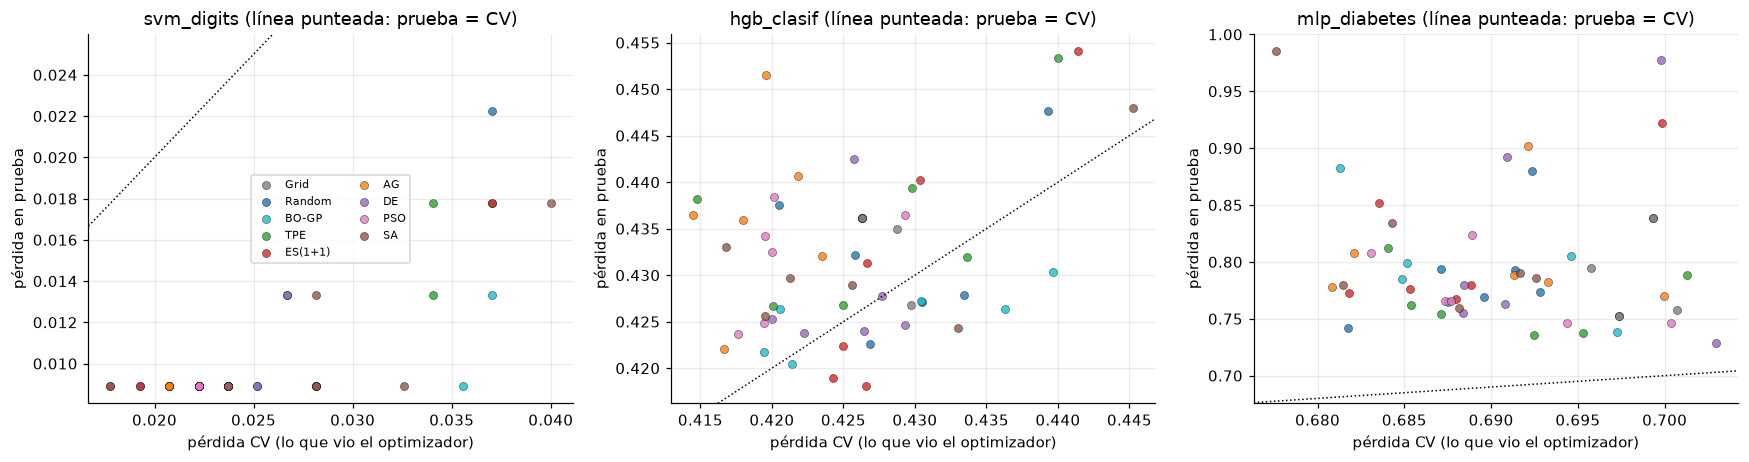

In [21]:
filas = []
for nombre, (esp, f, prueba) in REAL.items():
    sub = dfC[dfC.tarea == nombre]
    for _, r in sub.iterrows():
        filas.append(dict(tarea=nombre, alg=r["alg"], semilla=r["semilla"], cv=r["mejor"], prueba=prueba(r["u"])))
dfT = pd.DataFrame(filas)
dfT["brecha"] = dfT["prueba"] - dfT["cv"]

tab_test = dfT.groupby(["tarea", "alg"])[["cv", "prueba", "brecha"]].mean().round(4)
print("Brecha prueba − CV (media de 6 semillas; positiva = optimismo de la validación)")
print(dfT.pivot_table(index="alg", columns="tarea", values="brecha").loc[list(ALGOS)].round(4).to_string())
print()
print("Pérdida en el conjunto de prueba de la mejor configuración (media ± desv.)")
dsT = dfT.groupby(["tarea", "alg"])["prueba"].agg(["mean", "std"])
print(pd.DataFrame({a: {t: f"{dsT.loc[(t, a), 'mean']:.4f} ± {dsT.loc[(t, a), 'std']:.4f}" for t in REAL} for a in ALGOS}).T.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, nombre in zip(axes, REAL):
    s = dfT[dfT.tarea == nombre]
    for a in ALGOS:
        q = s[s.alg == a]
        ax.scatter(q["cv"], q["prueba"], color=COLOR[a], label=a, s=28, alpha=0.8, edgecolor="k", lw=0.3)
    ax.axline((s["cv"].mean(), s["cv"].mean()), slope=1, color="k", ls=":", lw=1)   # prueba = CV
    ax.set_title(nombre + " (línea punteada: prueba = CV)")
    ax.set_xlabel("pérdida CV (lo que vio el optimizador)"); ax.set_ylabel("pérdida en prueba")
axes[0].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()

**Lectura del conjunto de prueba.**

- **`svm_digits`: la brecha es negativa** (la prueba sale mejor que la CV). Es normal: la CV entrena con 2/3 del conjunto de entrenamiento y el modelo final con todo, y con 900 muestras el error es casi cero.
- **`hgb_clasif`: la brecha es pequeña y positiva** (del orden de 0.00–0.02): la selección es algo optimista pero no dramática.
- **`mlp_diabetes`: la brecha es grande** (≈ 0.07–0.14 en RMSE). Con solo 331 muestras de entrenamiento, el mínimo de muchas estimaciones ruidosas de CV es muy optimista (*winner's curse*), y el conjunto de prueba (111 muestras) también es ruidoso.
- **Lo más importante: el mejor en CV no es el mejor en prueba.** En `mlp_diabetes`, SA y ES (1+1), que obtuvieron las mejores pérdidas CV, son de los que peor quedan en prueba (la desviación entre semillas es de 0.06–0.08), mientras que TPE y PSO, con una CV algo peor, quedan mejor. Explotar más intensamente la pérdida de validación no garantiza mejor generalización, y con pocos datos hay que desconfiar de diferencias pequeñas.
- **Recomendación:** con datos escasos, usa validación cruzada repetida o anidada, regulariza el espacio de búsqueda (por ejemplo, limita la capacidad máxima) y reserva siempre un conjunto de prueba que nadie toque.

## 10. Guía de decisión, resumen, ejercicios y referencias

### Cuándo usar cada familia

| Situación | Recomendación | Por qué |
|---|---|---|
| 1–2 hiperparámetros, evaluación barata | **Grid Search** | Es exhaustivo, reproducible y fácil de visualizar |
| 3–6 hiperparámetros, nada de información previa | **Random Search** como punto de partida | Casi sin supuestos; robusto; paralelizable; línea base obligatoria |
| Evaluación **muy costosa** (minutos a horas) y pocas dimensiones continuas | **Bayesiana con GP** | Aprovecha cada evaluación; el costo propio $O(n^3)$ es irrelevante |
| Espacio **mixto, condicional o de dimensión media** | **TPE** | Lineal en $n$; admite categóricos y condicionales |
| Presupuesto **moderado/grande**, evaluación barata, paisaje rugoso o con óptimos locales | **Metaheurísticas** (DE, AG, SA) | No suponen suavidad; mantienen diversidad |
| Espacio **estructurado** (arquitecturas, permutaciones, selección de variables) | **Metaheurísticas** con operadores propios | Los clásicos no saben qué es un "vecino" válido (notebook [17](17-seleccion-de-caracteristicas-metaheuristicas.ipynb)) |
| Muchos trabajos en paralelo (cientos de GPUs) | **Poblacionales / Random** | Se evalúan generaciones enteras a la vez; los secuenciales (BO, SA) no escalan |

```
¿Cuántos hiperparámetros?
├─ 1–2 ──────────────────────────► Grid Search
├─ 3–10
│   ├─ ¿evaluación cara y espacio suave? ─► BO con GP
│   ├─ ¿espacio mixto / condicional?     ─► TPE
│   └─ ¿no sé nada / línea base?         ─► Random Search
└─ muchos o estructura combinatoria ─► Metaheurísticas (DE, AG, ...) + Random como control
```

### Resumen

- Los tres métodos clásicos **no son rivales débiles**: Random Search es una línea base difícil de superar con presupuestos pequeños, y las bayesianas son muy eficientes en pocas dimensiones.
- La **dimensión efectiva** y la **rugosidad del paisaje** explican casi todas las diferencias: Grid sufre con $d$ alto; GP sufre con $d$ alto *efectivo*; las metaheurísticas pagan su inicialización cuando el presupuesto es corto.
- El **presupuesto** cambia el orden: un método puede ganar a 20 evaluaciones y perder a 100.
- **Compara siempre contra Random** y con varias semillas. Una sola corrida no demuestra nada.
- Parte del "mejor valor de validación" es **optimismo de selección**: mide siempre en datos que el optimizador no vio.

### Ejercicios propuestos

1. **Presupuesto grande.** Repite el experimento A con $B=500$ y 10 semillas. ¿Qué pasa con el rango de BO-GP (mira el costo por iteración)? ¿Y con DE y PSO?
2. **Ruido.** Añade ruido gaussiano a `esfera_efectiva` ($\sigma=0.1$). ¿Qué métodos sufren más al comparar dos configuraciones con evaluaciones ruidosas? Prueba a reevaluar el mejor candidato.
3. **Categóricas.** Sustituye el kernel de Matérn por uno de Hamming para las dimensiones categóricas de `svm_digits`. ¿Mejora BO-GP?
4. **Paralelismo.** En lugar de un punto por iteración, evalúa lotes de 4 (*batch BO* con la heurística *constant liar*) y compara con DE/PSO, que ya son paralelos por naturaleza.
5. **Tu propio problema.** Define tu espacio con `Espacio` y tu pérdida con validación temporal, y compara Random, TPE y DE con 10 semillas.
6. **Hyperband.** Implementa *successive halving* (Jamieson & Talwalkar, 2016): evalúa muchas configuraciones con pocos recursos y descarta a las peores. ¿Cómo se combina con TPE (BOHB)?

### Referencias

- Bergstra, J. & Bengio, Y. (2012). *Random Search for Hyper-Parameter Optimization*. Journal of Machine Learning Research, 13, 281–305.
- Bergstra, J., Bardenet, R., Bengio, Y. & Kégl, B. (2011). *Algorithms for Hyper-Parameter Optimization*. Advances in Neural Information Processing Systems (NIPS) 24.
- Snoek, J., Larochelle, H. & Adams, R. P. (2012). *Practical Bayesian Optimization of Machine Learning Algorithms*. Advances in Neural Information Processing Systems (NIPS) 25.
- Jones, D. R., Schonlau, M. & Welch, W. J. (1998). *Efficient Global Optimization of Expensive Black-Box Functions*. Journal of Global Optimization, 13, 455–492.
- Rasmussen, C. E. & Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press.
- Bischl, B. et al. (2023). *Hyperparameter Optimization: Foundations, Algorithms, Best Practices, and Open Challenges*. WIREs Data Mining and Knowledge Discovery.
- Hutter, F., Kotthoff, L. & Vanschoren, J. (eds.) (2019). *Automated Machine Learning: Methods, Systems, Challenges*. Springer.
- Storn, R. & Price, K. (1997). *Differential Evolution: A Simple and Efficient Heuristic for Global Optimization over Continuous Spaces*. Journal of Global Optimization, 11, 341–359.
- Kennedy, J. & Eberhart, R. (1995). *Particle Swarm Optimization*. Proceedings of IEEE International Conference on Neural Networks.
- Kirkpatrick, S., Gelatt, C. D. & Vecchi, M. P. (1983). *Optimization by Simulated Annealing*. Science, 220, 671–680.
- Rechenberg, I. (1973). *Evolutionsstrategie: Optimierung technischer Systeme nach Prinzipien der biologischen Evolution*. Frommann-Holzboog.
- Jamieson, K. & Talwalkar, A. (2016). *Non-stochastic Best Arm Identification and Hyperparameter Optimization*. AISTATS.
- Wolpert, D. H. & Macready, W. G. (1997). *No Free Lunch Theorems for Optimization*. IEEE Transactions on Evolutionary Computation, 1(1), 67–82.
- Demšar, J. (2006). *Statistical Comparisons of Classifiers over Multiple Data Sets*. Journal of Machine Learning Research, 7, 1–30.